# Integrated Data Science Project: Who Survived the Titanic, and Can We Predict It?
**Master notebook (Week 6).** This notebook runs the *entire* pipeline, from the raw file to the final figures, by calling the functions in `src/titanic_project`. It produces exactly the numbers in the integrated report and finishes with a determinism check against `python run_pipeline.py`.

| Item | Description |
|---|---|
| **Real-world problem** | In a mass-casualty maritime evacuation, which passenger characteristics were associated with survival, and how well can survival be predicted from information known at boarding? The answers show how access to safety was unequal and how far a data-driven model can go. |
| **Data** | Public Titanic passenger manifest, 891 passengers, 12 columns (source URL and SHA-256 hash recorded). |
| **Techniques** | Data cleaning, exploratory analysis, hypothesis testing, logistic regression, machine learning with nested cross-validation, data visualization. |
| **Success criteria** | (1) cleaned dataset that passes automated checks; (2) statistically supported answers with effect sizes and uncertainty; (3) a predictive model evaluated on unseen data and compared with a classical benchmark; (4) every number reproducible by one command. |

**Stages:** 1 Ingest, 2 Clean, 3 Explore, 4 Statistical modelling, 5 Machine learning, 6 Visualization, 7 Integration.

## 0. Setup

In [1]:
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from titanic_project import config, data, cleaning, eda, inference, modeling, viz, integrate, results as res
pd.set_option("display.float_format", lambda v: f"{v:,.3f}"); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
config.ensure_dirs(); viz.style(); T0 = time.time()
def show(name, width=900): display(Image(filename=str(config.FIG_DIR / f"{name}.png"), width=width))
print("project root:", ROOT)

project root: /home/claude/proj/titanic-ds-project


## 1. Ingest: data collection and provenance
The raw file is loaded exactly as published. Its SHA-256 hash is recorded so that any later change to the input is detectable.

In [2]:
raw = data.load_raw(); prov = data.provenance(raw)
print(f"{prov['n_rows']} rows x {prov['n_cols']} columns | SHA-256 {prov['sha256'][:16]}... | duplicates: {prov['duplicate_rows']} rows, {prov['duplicate_ids']} ids")
print("missing values:", prov["missing"], "| overall survival rate:", round(prov["survival_rate"], 4))
pd.DataFrame({"column": list(data.RAW_SCHEMA), "description": list(data.RAW_SCHEMA.values()), "dtype": [prov["dtypes"][c] for c in data.RAW_SCHEMA]})

891 rows x 12 columns | SHA-256 4a437fde05fe5264... | duplicates: 0 rows, 0 ids
missing values: {'Age': 177, 'Cabin': 687, 'Embarked': 2} | overall survival rate: 0.3838


,column,description,dtype
0,PassengerId,Unique row identifier,int64
1,Survived,"Outcome: 1 = survived, 0 = died",int64
2,Pclass,"Ticket class (1 = first, 2 = second, 3 = third)",int64
3,Name,Passenger name including title,str
4,Sex,male / female,str
5,Age,Age in years (fractional for infants); missing...,float64
6,SibSp,Number of siblings or spouses aboard,int64
7,Parch,Number of parents or children aboard,int64
8,Ticket,Ticket number (shared by passengers travelling...,str
9,Fare,Fare in pounds sterling for the ticket,float64


## 2. Clean: preprocessing with logged decisions
Three columns need attention (age 19.9% missing, cabin 77.1% missing, port 2 values). Each decision is documented and checked by nine automated assertions. No rows are deleted.

In [3]:
df, log = cleaning.clean(raw)
df.to_csv(config.CLEAN_PATH, index=False); dd = cleaning.data_dictionary(df); dd.to_csv(config.PROCESSED_DIR / "data_dictionary.csv", index=False)
decisions = pd.DataFrame([
    ["Age (177 missing)", "Median age by title x class; Age_Imputed flag keeps it traceable"],
    ["Cabin (687 missing)", "Not imputed (77% missing); replaced by Has_Cabin flag and Deck"],
    ["Embarked (2 missing)", f"Filled with the mode ({log['embarked_imputed_with']}, {log['embarked_mode_pct']}% of passengers)"],
    ["Fare (skew %.2f, %d zero fares)" % (log["fare_skew_raw"], log["fare_zero"]), f"Kept; zero fares flagged; capped at the 99th percentile ({log['fare_cap_p99']}); log transform (skew {log['fare_skew_log']})"],
    ["Names / titles", f"Whitespace stripped; {log['n_titles_raw']} raw titles standardised to {log['n_titles_clean']} groups"],
    ["Shared tickets", "Ticket_Size and Fare_Per_Person derived"]], columns=["Issue", "Decision"])
display(decisions); print("quality checks:", log["checks"]); print("cleaned shape:", df.shape)
dd.head(8)

,Issue,Decision
0,Age (177 missing),Median age by title x class; Age_Imputed flag ...
1,Cabin (687 missing),Not imputed (77% missing); replaced by Has_Cab...
2,Embarked (2 missing),"Filled with the mode (S, 72.4% of passengers)"
3,"Fare (skew 4.79, 15 zero fares)",Kept; zero fares flagged; capped at the 99th p...
4,Names / titles,Whitespace stripped; 17 raw titles standardise...
5,Shared tickets,Ticket_Size and Fare_Per_Person derived


quality checks: {'no_missing_values': True, 'no_duplicate_rows': True, 'unique_passenger_id': True, 'survived_binary': True, 'pclass_1_to_3': True, 'age_in_0_to_100': True, 'fare_non_negative': True, 'family_size_consistent': True, 'age_minmax_in_unit_interval': True}
cleaned shape: (891, 26)


,column,type,origin,description,n_unique,missing
0,PassengerId,int,original,Unique row identifier,891,0
1,Survived,int8,original,"Outcome: 1 = survived, 0 = died",2,0
2,Pclass,ordered category,original,Ticket class 1 < 2 < 3 (1 = first),3,0
3,Name,text,cleaned,Passenger name; whitespace normalised,891,0
4,Sex,category,cleaned,Male / Female,2,0
5,Age,float,imputed,Age in years; missing values filled with media...,88,0
6,SibSp,int,original,Siblings or spouses aboard,7,0
7,Parch,int,original,Parents or children aboard,7,0


## 3. Explore: descriptive statistics, group rates and association tests

In [4]:
E = eda.run(df, raw)
display(pd.DataFrame(E["descriptive"]))
rates = pd.DataFrame([{"group": g, **{k: r[k] for k in ("level", "survived", "n", "rate", "lo", "hi")}} for g in ("Sex", "Pclass", "Embarked", "Age_Group", "Family_group") for r in E["rates"][g]])
display(rates)
display(pd.DataFrame(E["tests"])[["test", "method", "statistic", "p_bonferroni", "effect", "effect_name", "significant"]])
print("sex gap (women - men): %.1f points, 95%% bootstrap CI %.1f to %.1f" % (100 * E["sex_gap"]["gap"], 100 * E["sex_gap"]["ci"][0], 100 * E["sex_gap"]["ci"][1]))

,variable,count,mean,median,std,min,max,IQR,skew,kurtosis
0,Age,891.000,29.130,26.000,13.490,0.400,80.000,15.750,0.470,0.590
1,Fare,891.000,32.200,14.450,49.690,0.000,512.330,23.090,4.790,33.400
2,Fare_Per_Person,891.000,17.790,8.850,21.220,0.000,221.780,16.530,4.380,28.580
3,SibSp,891.000,0.520,0.000,1.100,0.000,8.000,1.000,3.700,17.880
4,Parch,891.000,0.380,0.000,0.810,0.000,6.000,0.000,2.750,9.780
5,Family_Size,891.000,1.900,1.000,1.610,1.000,11.000,1.000,2.730,9.160
6,Ticket_Size,891.000,1.790,1.000,1.360,1.000,7.000,1.000,2.220,4.780


,group,level,survived,n,rate,lo,hi
0,Sex,Female,233,314,0.742,0.691,0.787
1,Sex,Male,109,577,0.189,0.159,0.223
2,Pclass,1,136,216,0.630,0.563,0.691
3,Pclass,2,87,184,0.473,0.402,0.545
4,Pclass,3,119,491,0.242,0.207,0.282
5,Embarked,Cherbourg,93,168,0.554,0.478,0.627
6,Embarked,Queenstown,30,77,0.390,0.288,0.501
7,Embarked,Southampton,219,646,0.339,0.304,0.376
8,Age_Group,Child,41,72,0.569,0.454,0.677
9,Age_Group,Teen,22,45,0.489,0.350,0.630


,test,method,statistic,p_bonferroni,effect,effect_name,significant
0,Survival vs Sex,Chi-square,263.051,0.000,0.543,Cramer's V,True
1,Survival vs Pclass,Chi-square,102.889,0.000,0.340,Cramer's V,True
2,Survival vs Embarked,Chi-square,25.964,0.000,0.171,Cramer's V,True
3,Survival vs Is_Alone,Chi-square,36.850,0.000,0.203,Cramer's V,True
4,Survival vs Has_Cabin,Chi-square,89.486,0.000,0.317,Cramer's V,True
5,"Age, survivors vs non-survivors",Mann-Whitney U,"89,267.500",1.000,-0.049,rank-biserial,False
6,"log Fare, survivors vs non-survivors",Mann-Whitney U,"129,951.500",0.000,0.384,rank-biserial,True
7,Age across Pclass,Kruskal-Wallis,155.924,0.000,0.173,epsilon-squared,True


sex gap (women - men): 55.3 points, 95% bootstrap CI 49.4 to 61.0


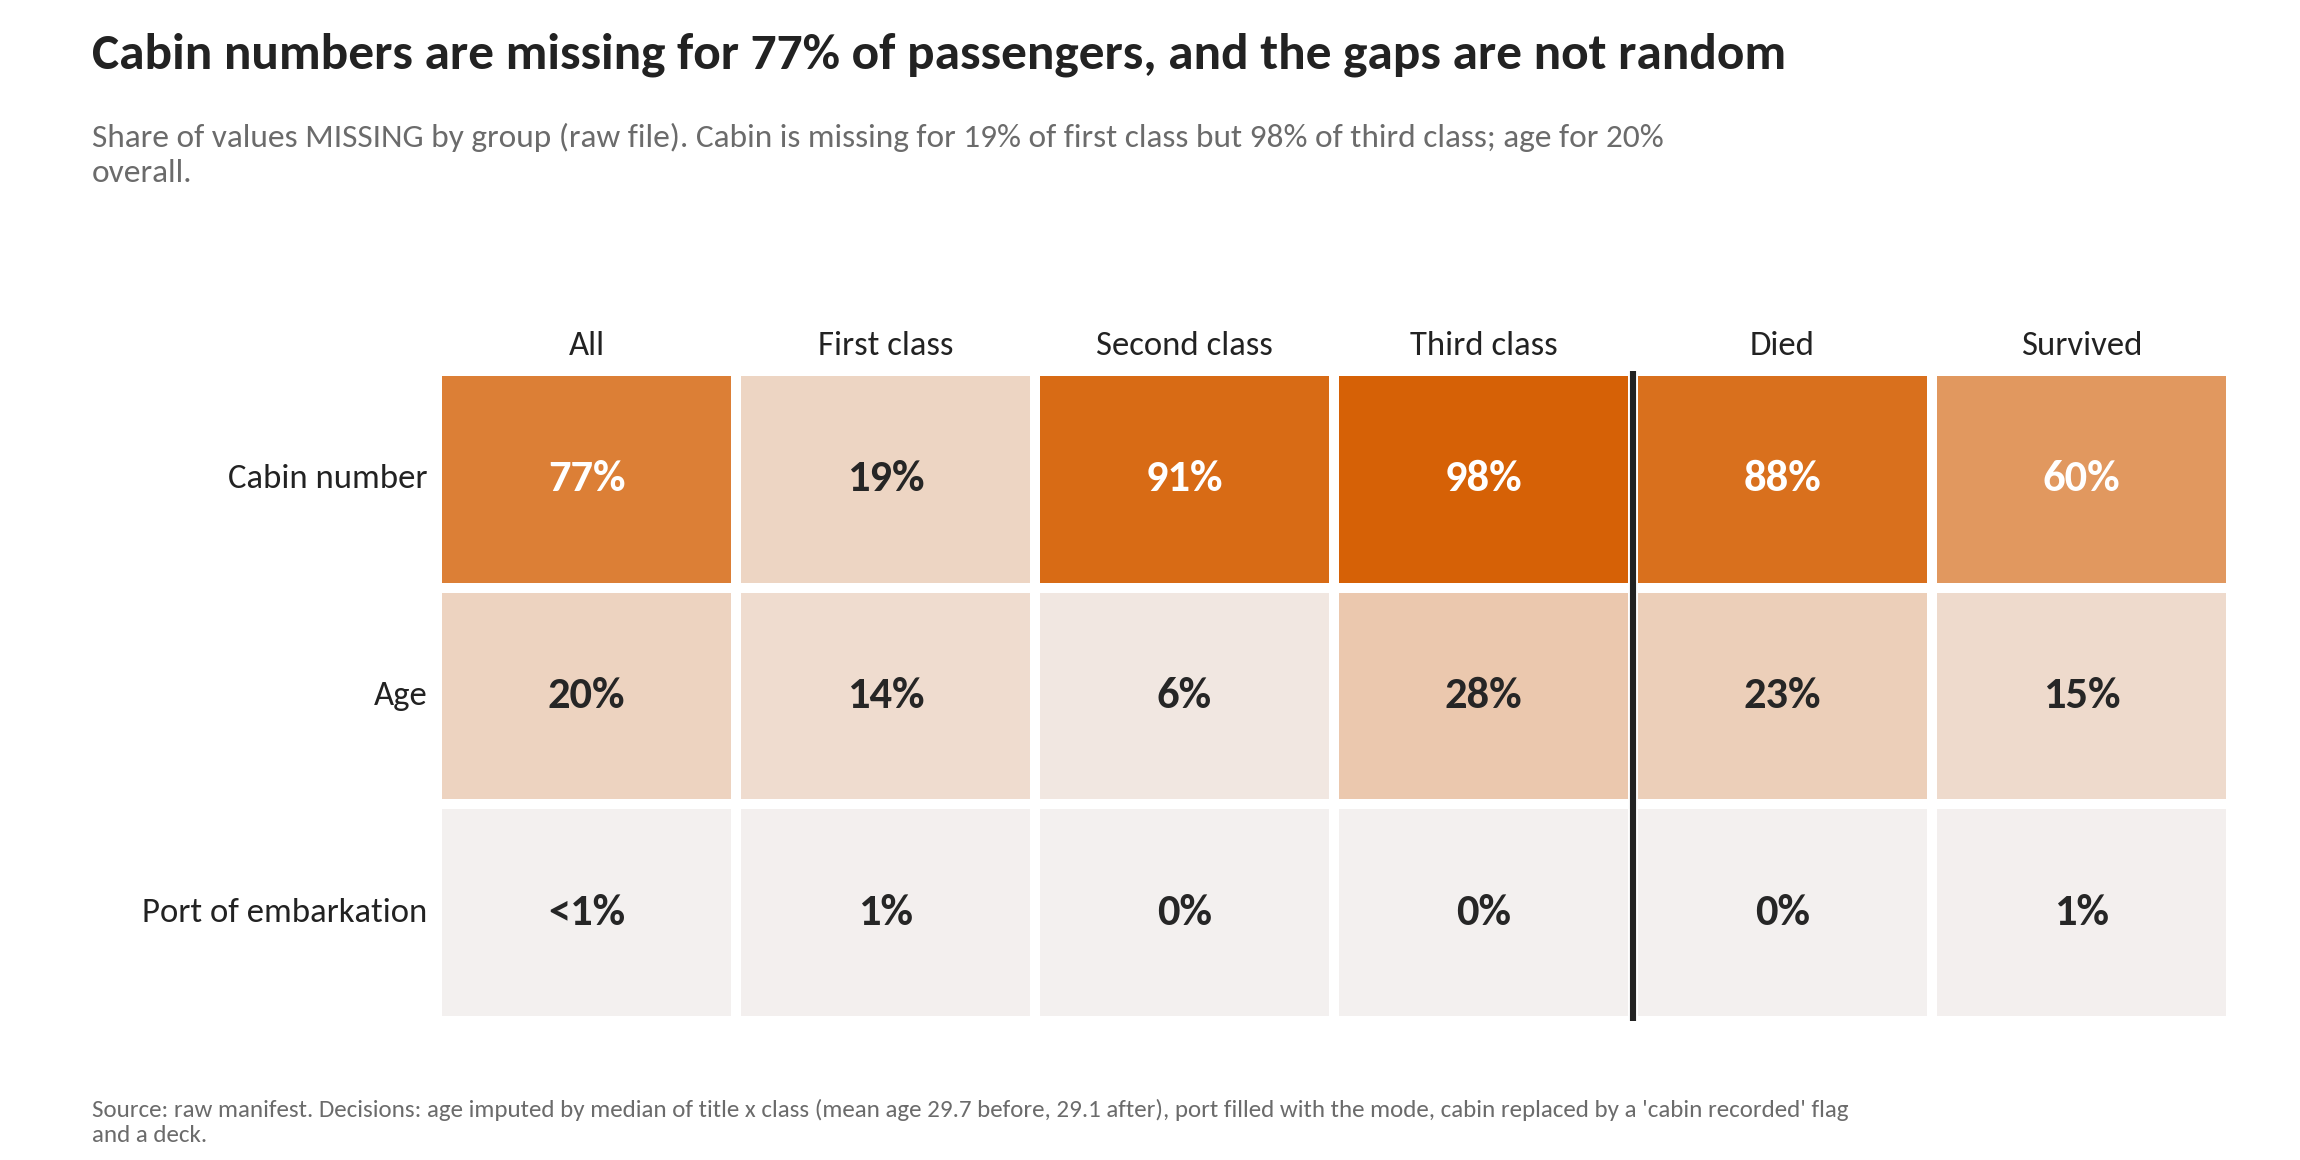

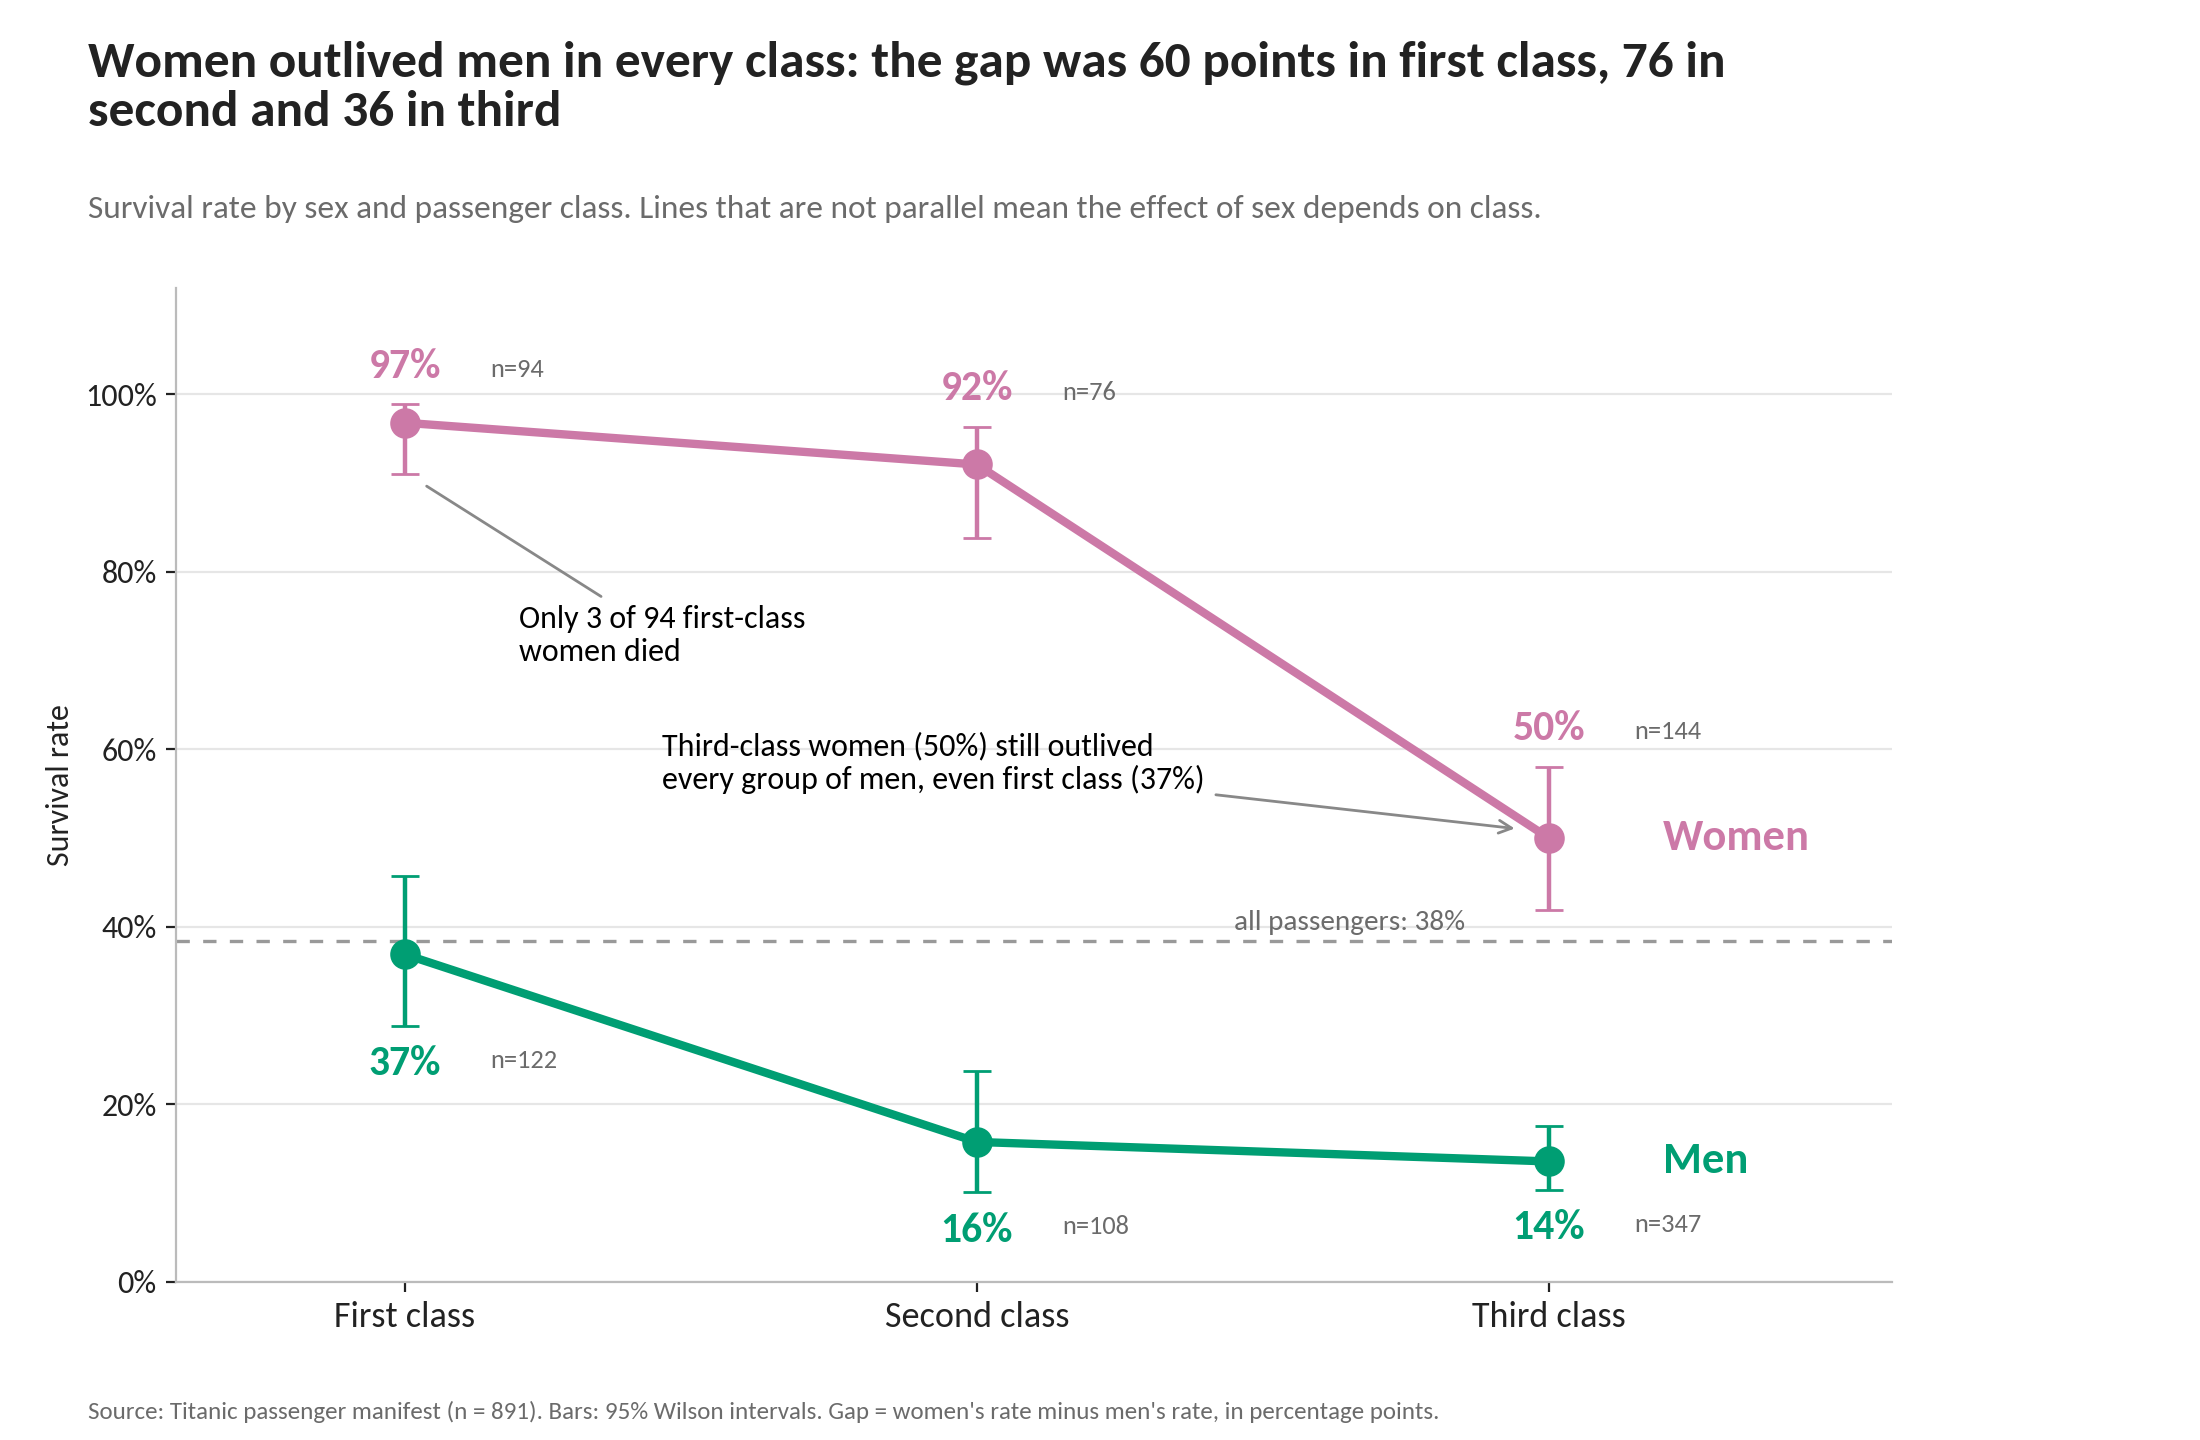

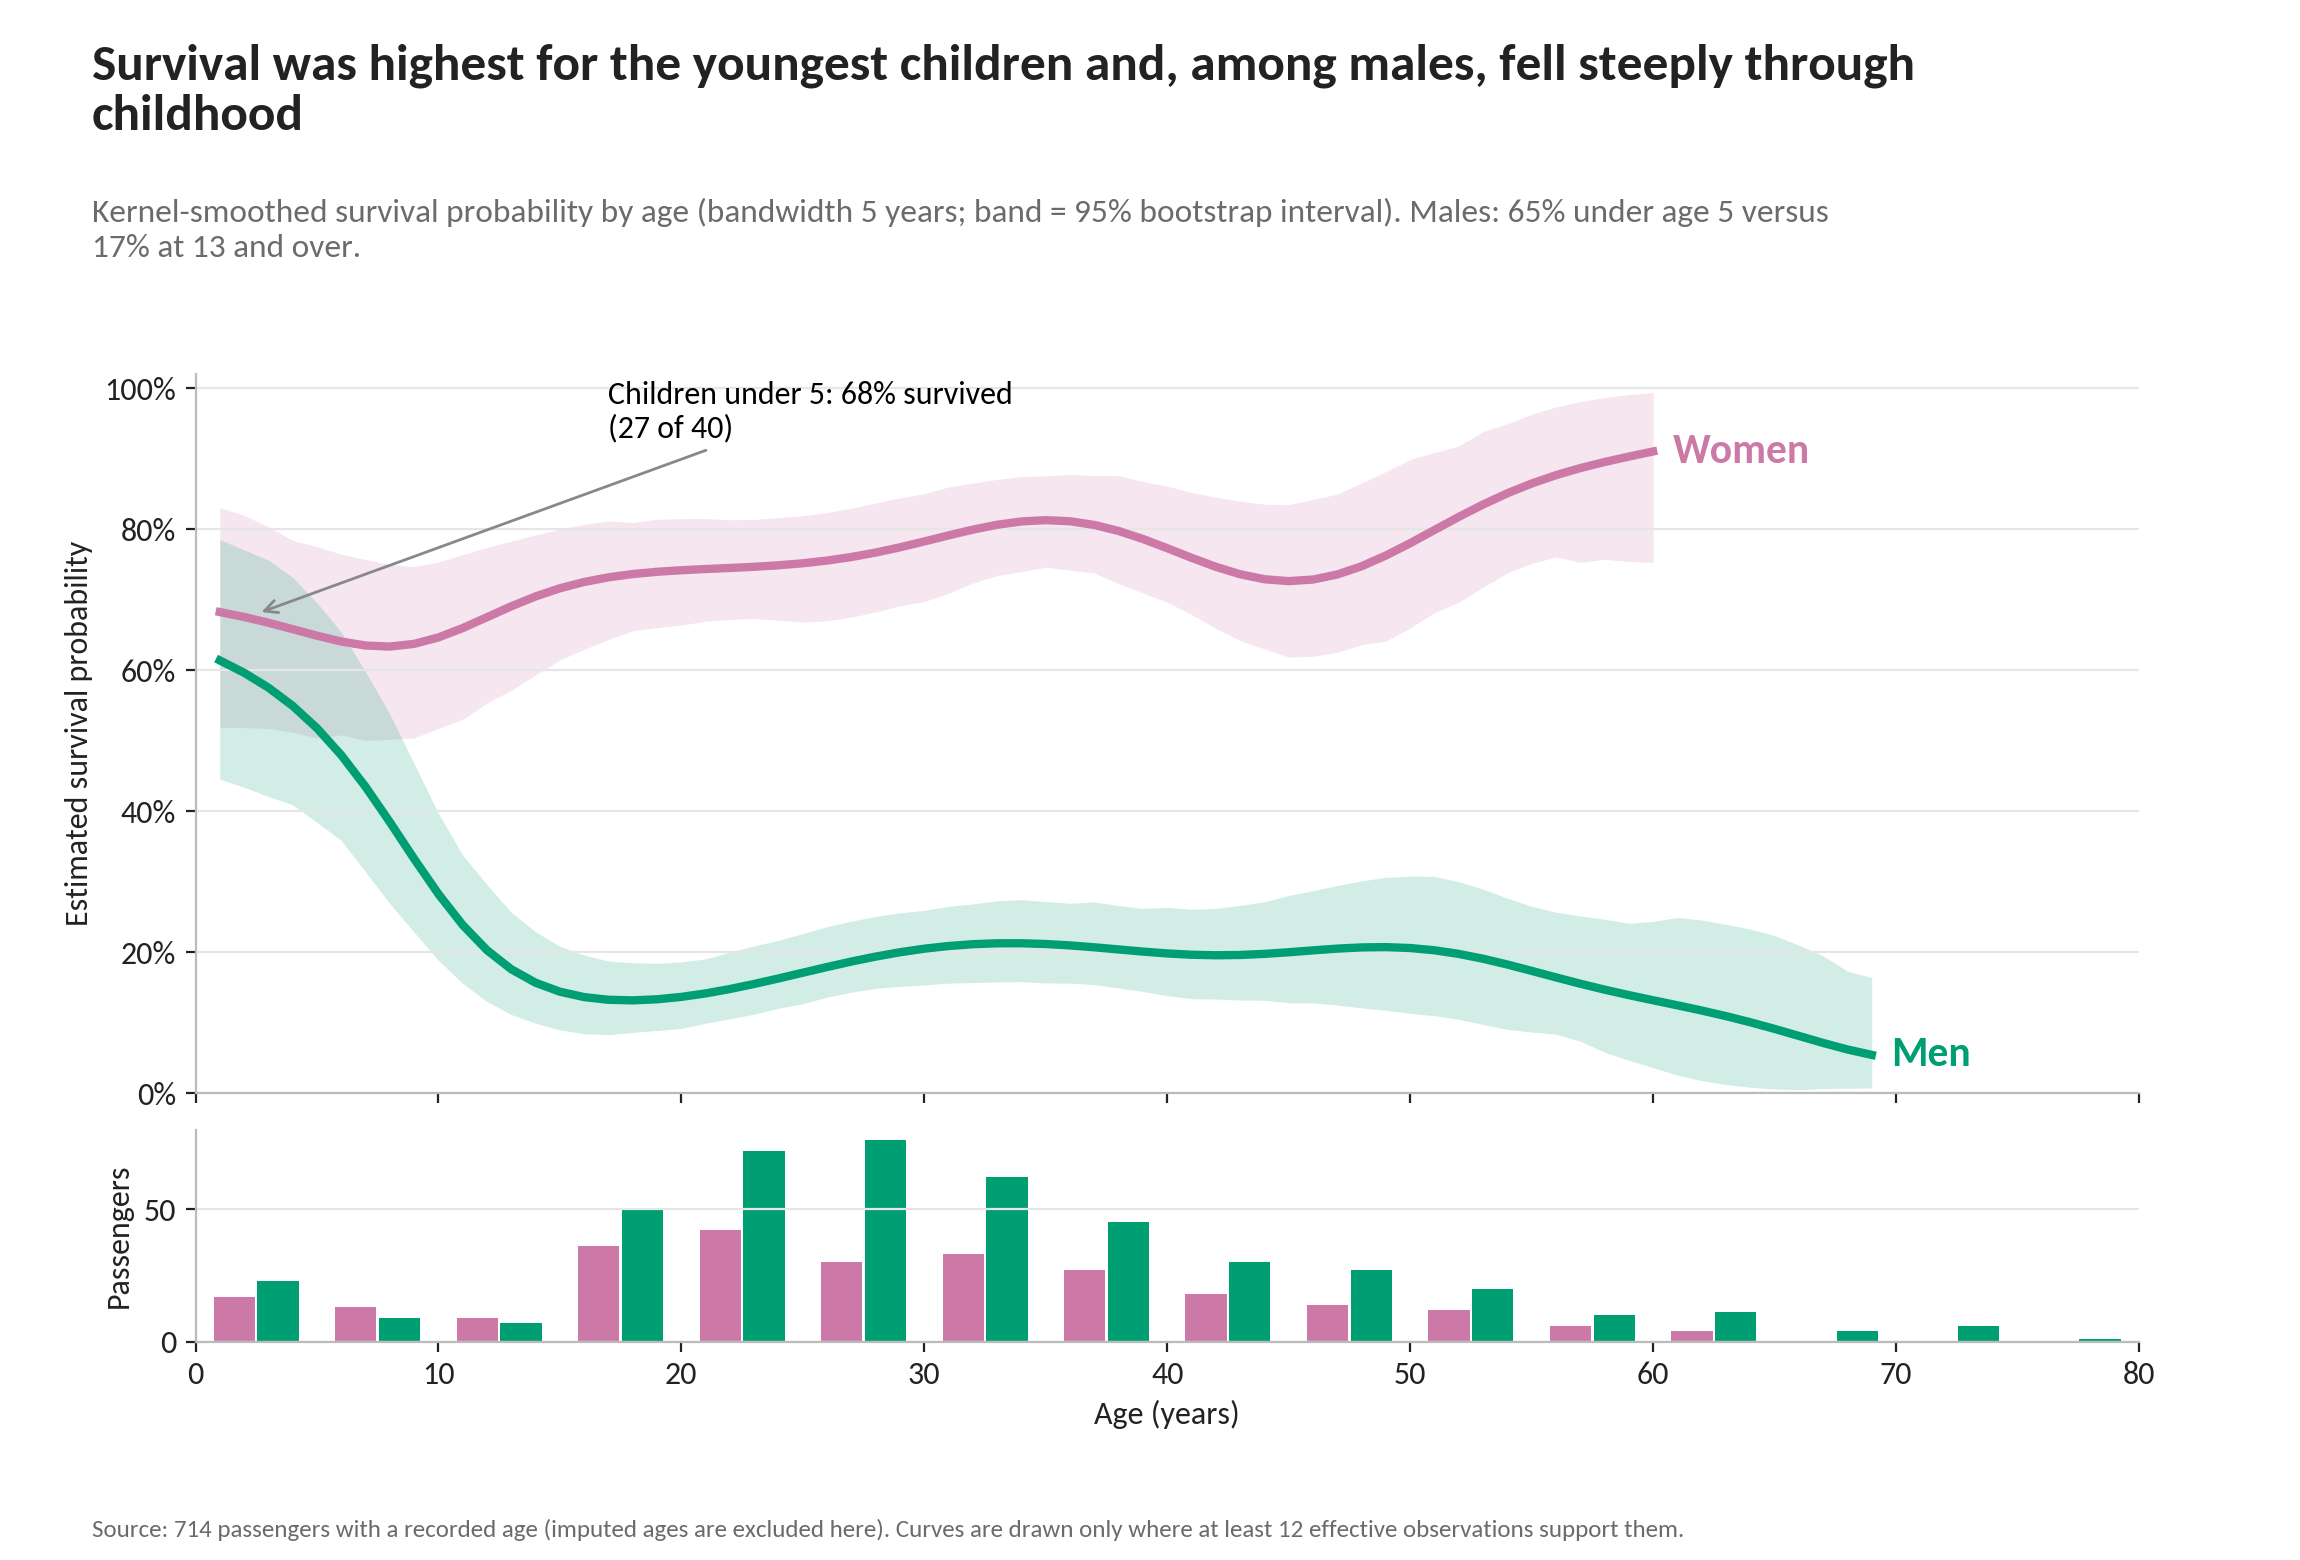

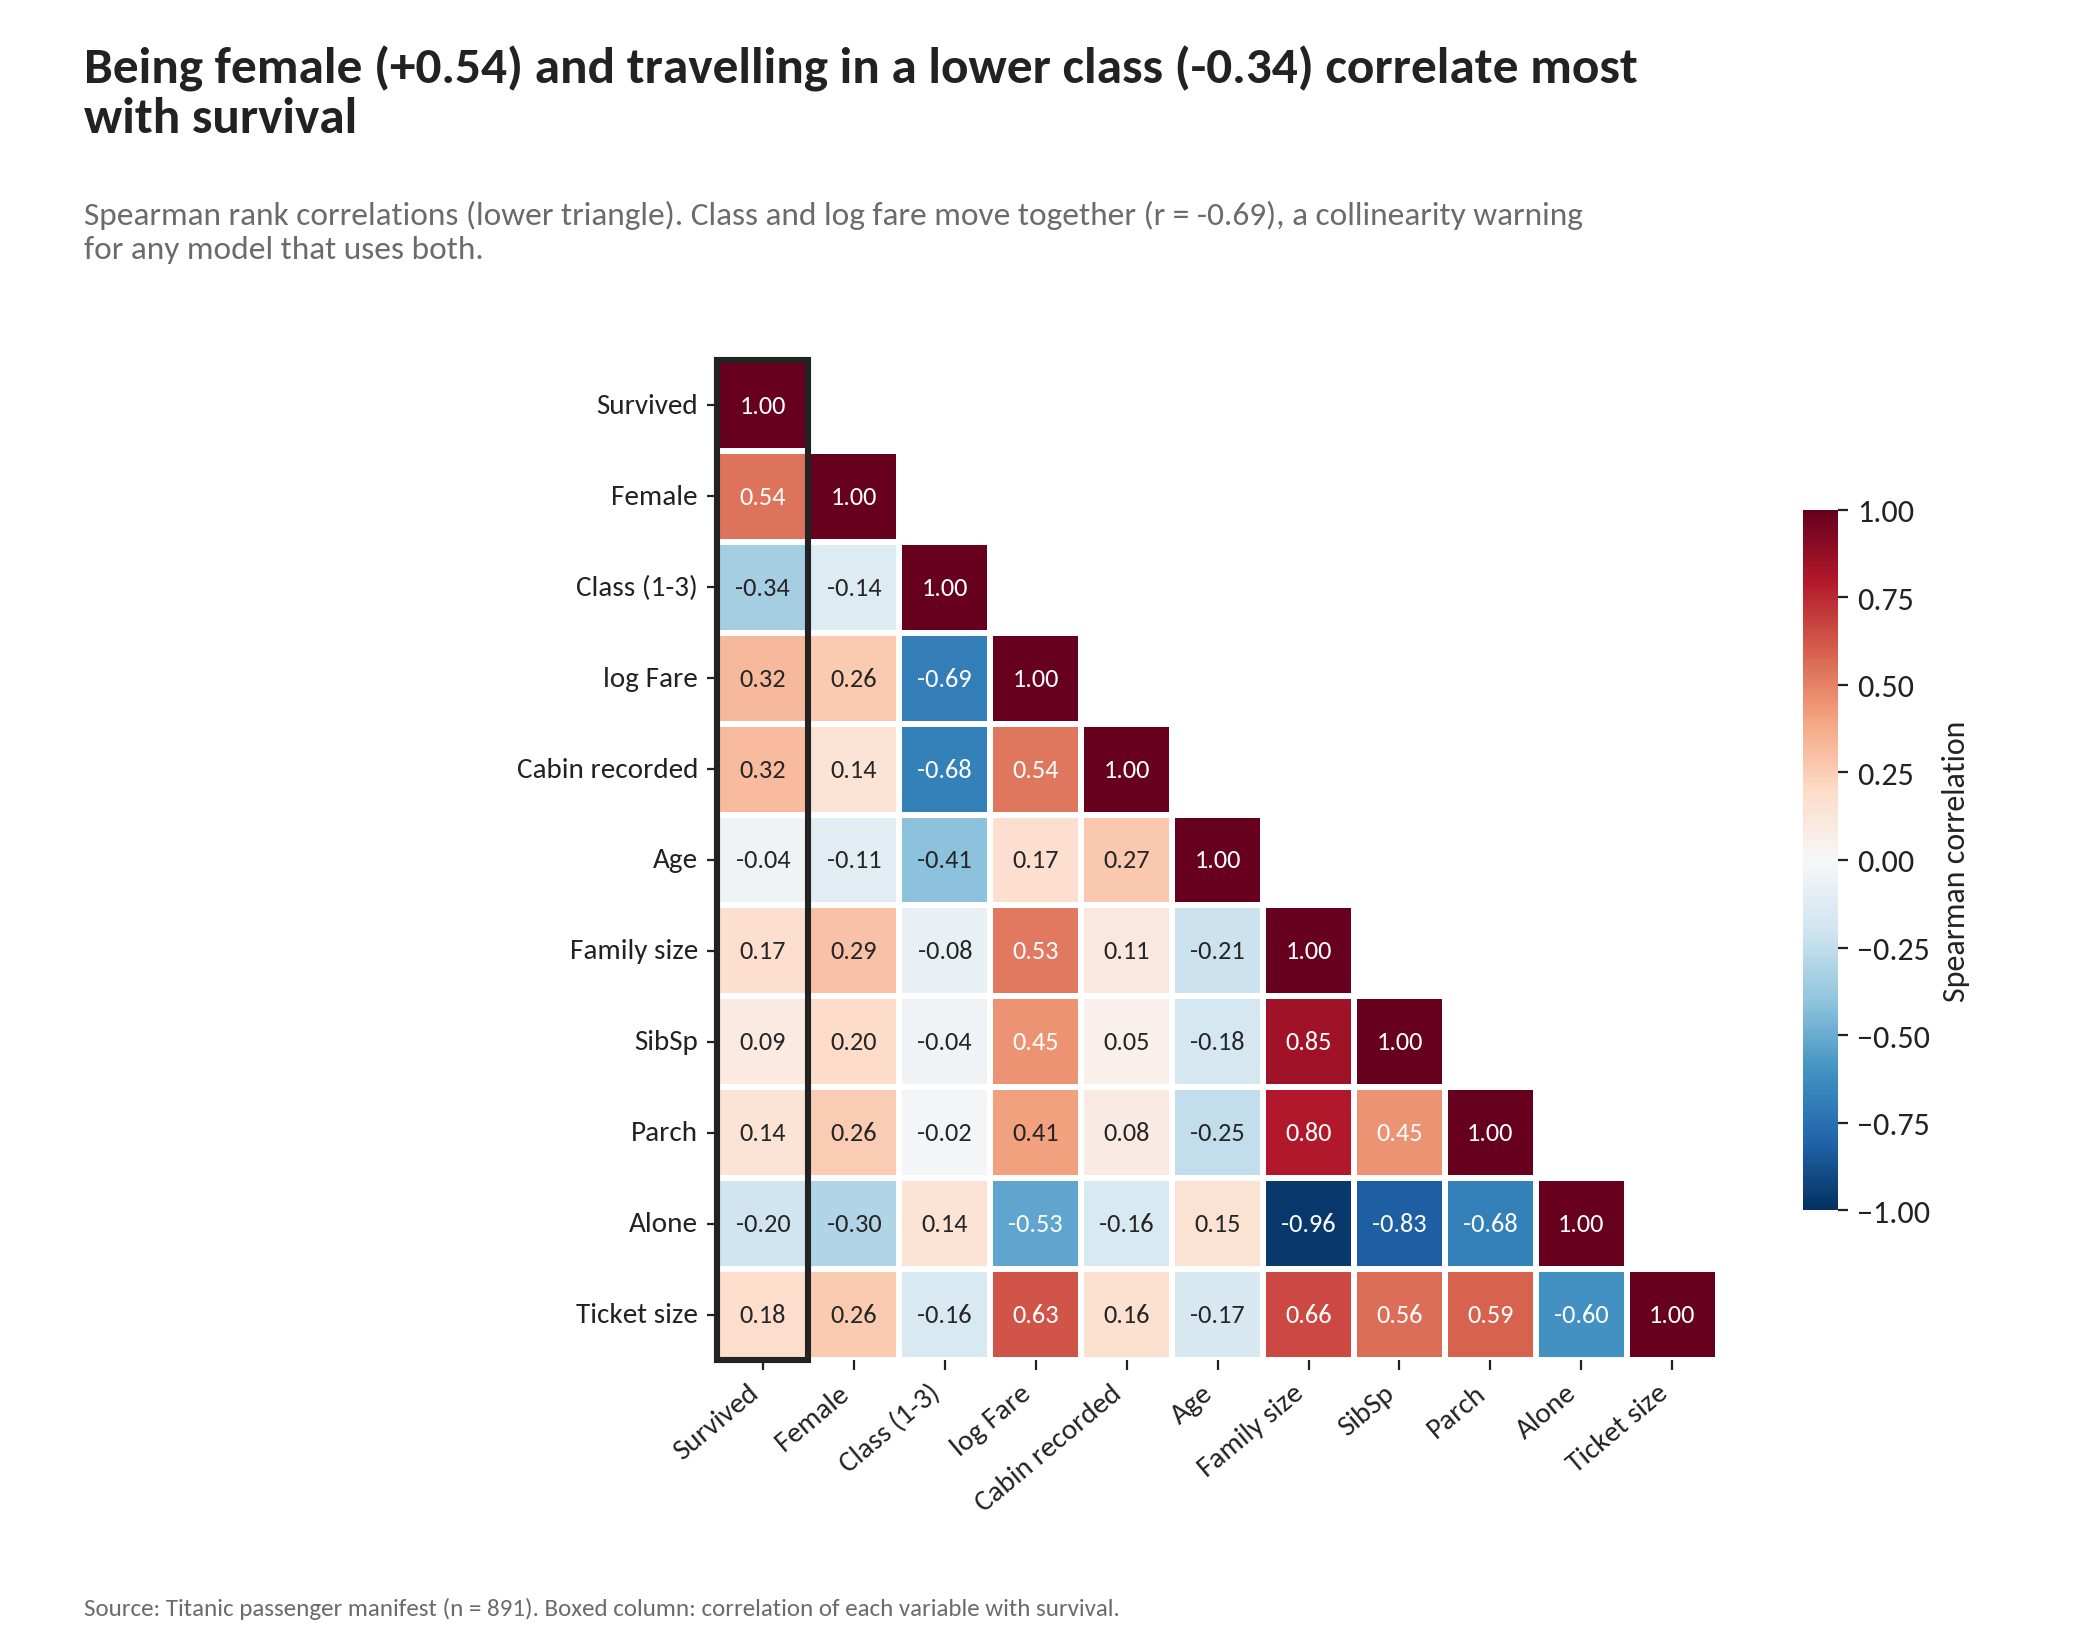

In [5]:
viz.fig_data_quality(E, log); viz.fig_sex_class(E); viz.fig_age(df); viz.fig_correlation(E)
for n in ("fig02_data_quality", "fig03_sex_by_class", "fig04_age_curves", "fig05_correlation"): show(n)

**Reading the EDA.** Survival was 38.4% overall but ranged from 14% (third-class men) to 97% (first-class women). Sex (Cramér's V 0.54) and class (V 0.34) show the strongest associations; the women's advantage was 60, 76 and 36 percentage points in first, second and third class. Age matters mostly for the very young, and the missing cabin numbers follow class and outcome, so the cabin record cannot be treated as random. Class and fare are strongly correlated (r = -0.69), a warning for modelling.

## 4. Statistical modelling: logistic regression and hypothesis tests
The model is built stepwise and compared with likelihood-ratio tests and information criteria. Assumptions are checked first, and the one that fails (linearity in age) is fixed.

In [6]:
I = inference.run(df)
A = I["assumptions"]
print(f"events per variable {A['events_per_variable']} | largest VIF {A['vif_max']:.2f} | Box-Tidwell p for a straight-line age effect {A['boxtidwell_age_p']:.4f} (violated)")
display(pd.DataFrame(I["age_forms"])); print("curvature left after log(Age): p = %.2f" % I["age_resid_curvature_p"])
display(pd.DataFrame(I["compare"])); display(pd.DataFrame(I["lrt"]))
print("block tests:", {k: (round(v["chi2"], 1), round(v["p"], 4)) for k, v in I["blocks"].items()})

events per variable 42.8 | largest VIF 3.83 | Box-Tidwell p for a straight-line age effect 0.0011 (violated)


,form,k,logLik,AIC,BIC,HL_p
0,Linear in Age,11,-369.571,761.141,813.857,0.014
1,Quadratic in Age,12,-365.119,754.237,811.745,0.130
2,Child indicator (<13) + linear,12,-362.182,748.363,805.871,0.158
3,Piecewise linear (knot at 15),12,-359.989,743.979,801.487,0.203
4,Natural cubic spline (3 df),12,-366.075,756.149,813.658,0.063
5,log(Age),11,-361.020,744.039,796.755,0.422


curvature left after log(Age): p = 0.68


,model,k,logLik,AIC,BIC,McFadden_R2
0,M0 null,1,-593.328,"1,188.655","1,193.447",0.000
1,M1 sex + class,4,-413.444,834.888,854.058,0.303
2,"M2 + age, family, port",9,-377.792,773.585,816.716,0.363
3,M3 + sex x class,11,-361.020,744.039,796.755,0.392
4,M4 + sex x age,12,-356.533,737.066,794.574,0.399


,from,to,chi2,df,p
0,M0 null,M1 sex + class,359.767,3,0.000
1,M1 sex + class,"M2 + age, family, port",71.304,5,0.000
2,"M2 + age, family, port",M3 + sex x class,33.545,2,0.000
3,M3 + sex x class,M4 + sex x age,8.973,1,0.003


block tests: {'age': (49.7, 0.0), 'family_both': (28.8, 0.0), 'family_quad': (7.5, 0.0061), 'port': (3.4, 0.1866), 'interaction': (33.5, 0.0)}


,OR,OR_low,OR_high,p,p_robust
term,,,,,
Intercept,24.639,7.042,86.200,0.000,0.000
"Female (first class, vs male)",50.594,14.879,172.040,0.000,0.000
Second class (men),0.183,0.087,0.383,0.000,0.000
Third class (men),0.172,0.100,0.298,0.000,0.000
log(Age),0.351,0.253,0.487,0.000,0.000
"Family size, linear (centred)",0.969,0.748,1.256,0.814,0.809
"Family size, squared",0.900,0.829,0.977,0.012,0.037
Cherbourg (vs Southampton),1.445,0.890,2.346,0.136,0.135
Queenstown (vs Southampton),1.507,0.812,2.797,0.193,0.139


,class,OR,low,high,p
0,First,50.594,14.878,172.044,0.000
1,Second,100.221,34.899,287.804,0.000
2,Third,6.255,3.791,10.320,0.000


final model: LR chi2 = 464.6, McFadden R2 = 0.392, Nagelkerke R2 = 0.552, AIC = 744.0; Hosmer-Lemeshow p = 0.42
age: odds ratio per doubling 0.48 (0.39 to 0.61)


,model,AUC,AUC_sd,Accuracy,Brier
0,Sex only,0.767,0.028,0.787,0.167
1,M1 sex + class,0.833,0.031,0.787,0.149
2,"M2 + age, family, port",0.859,0.030,0.815,0.136
3,M3 + sex x class,0.865,0.033,0.817,0.130
4,M4 + sex x age,0.866,0.033,0.819,0.128


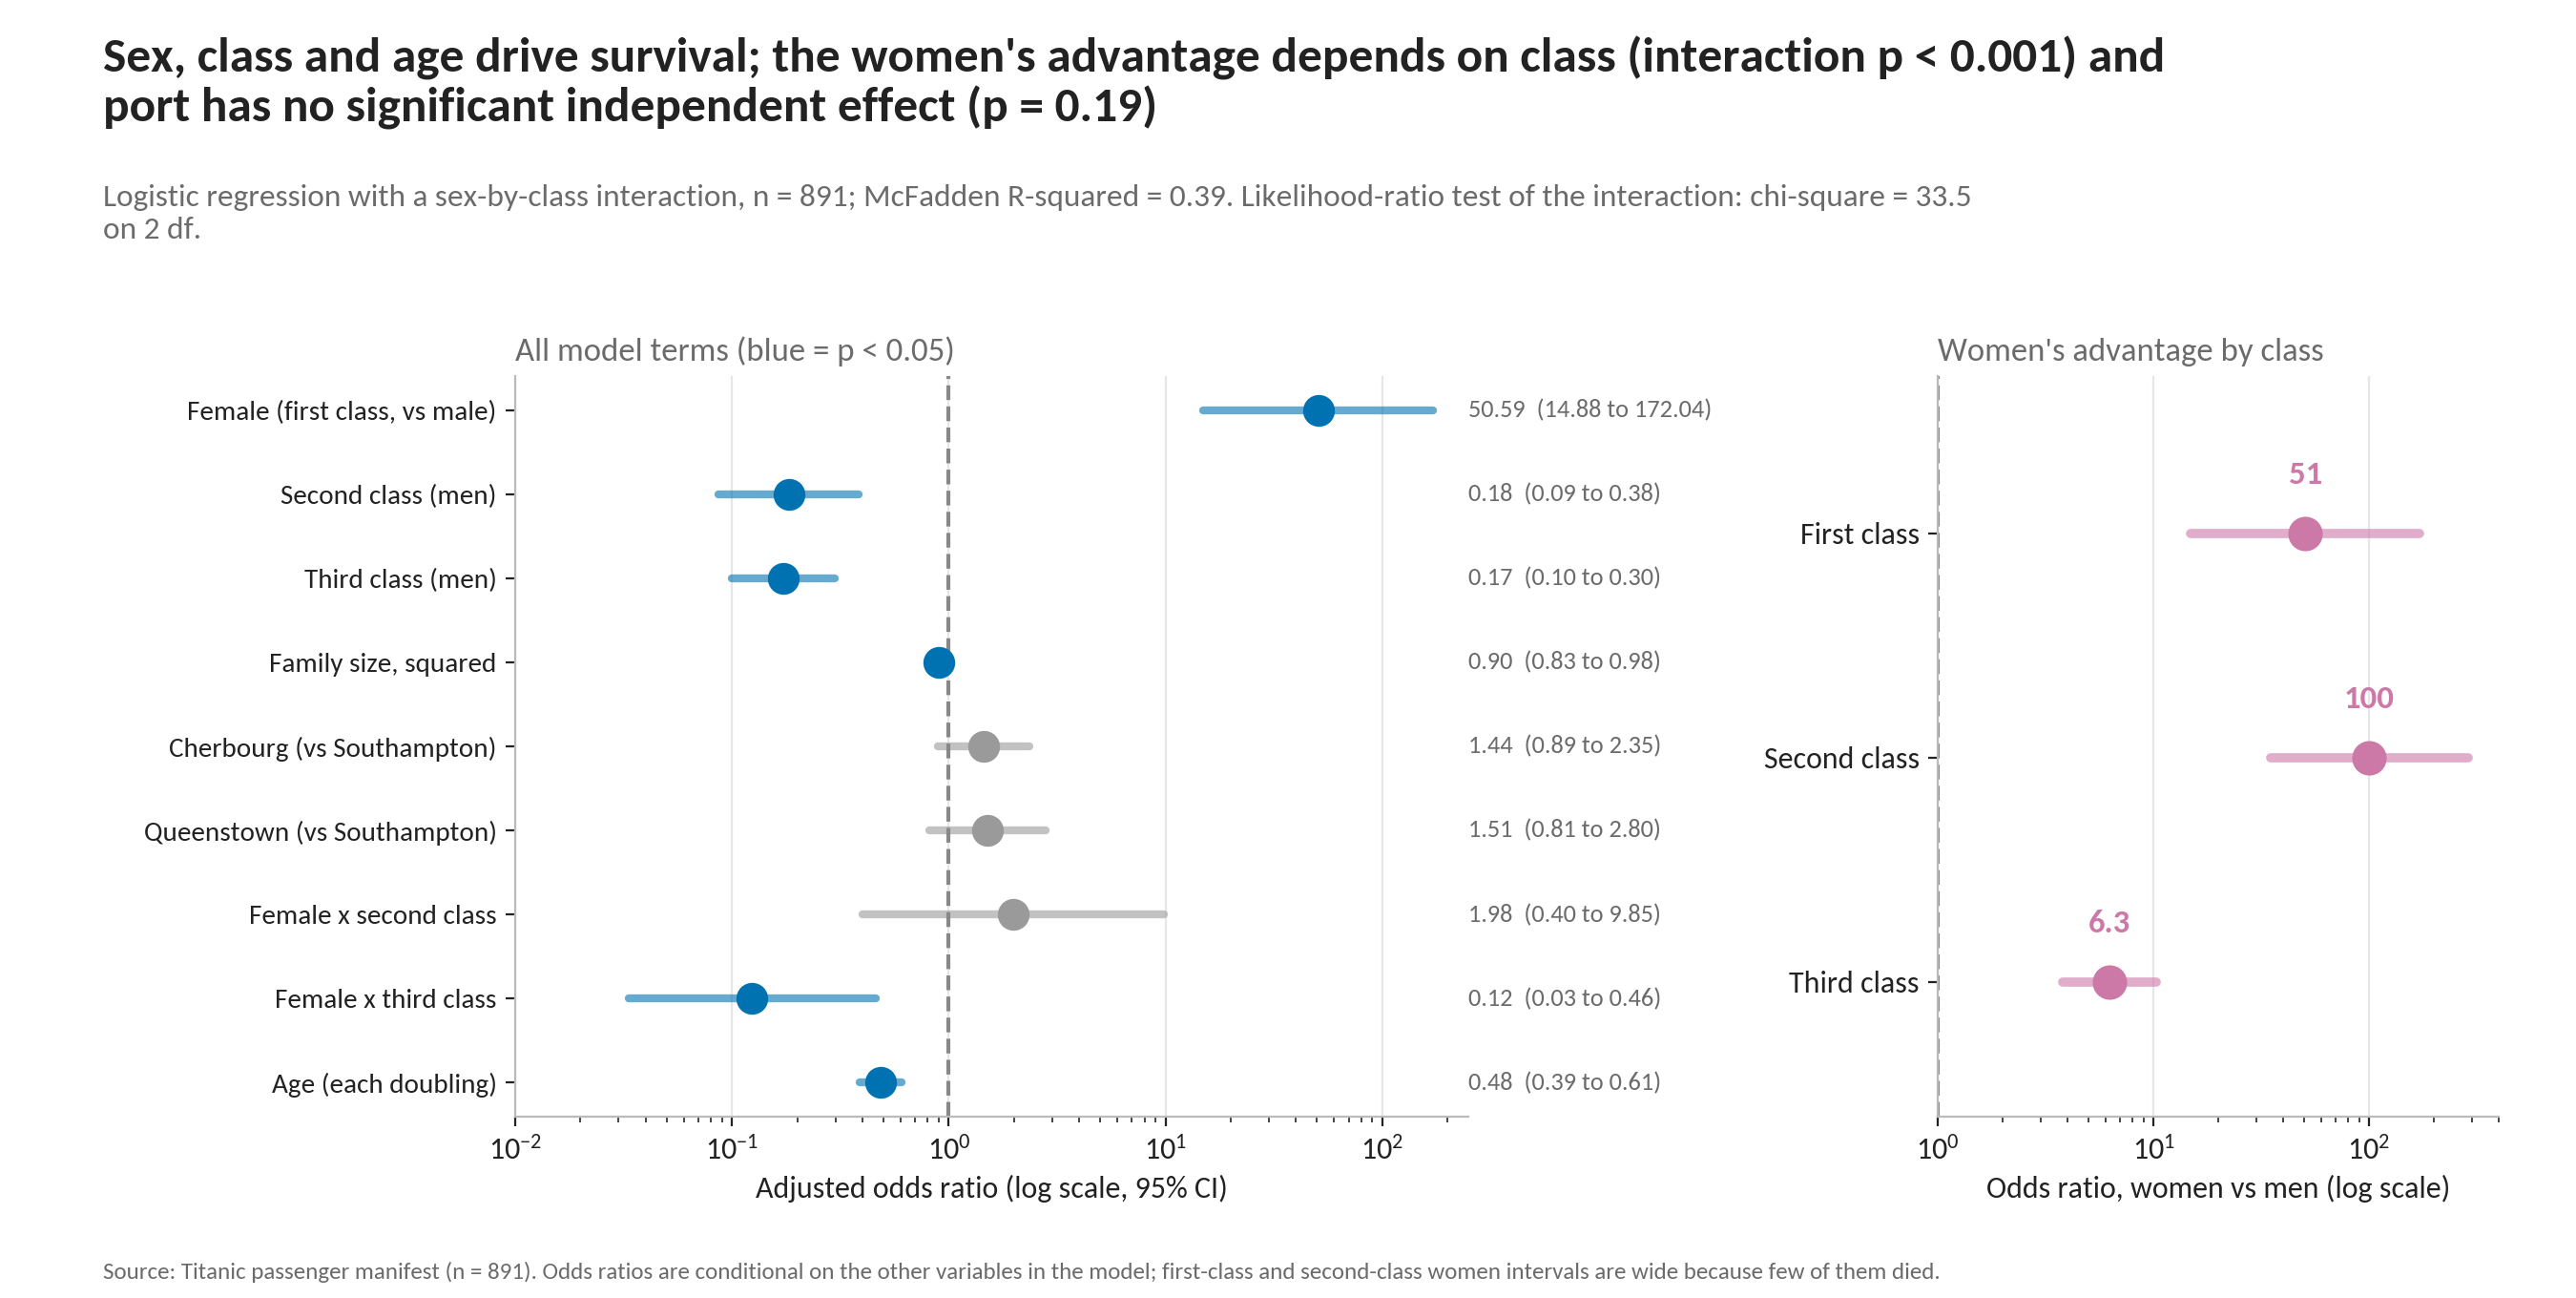

In [7]:
display(pd.DataFrame(I["coef"]).set_index("term"))
display(pd.DataFrame(I["sex_or_by_class"]))
f = I["final_fit"]; h = I["hosmer_lemeshow"]
print(f"final model: LR chi2 = {f['lr_chi2']:.1f}, McFadden R2 = {f['mcfadden']:.3f}, Nagelkerke R2 = {f['nagelkerke']:.3f}, AIC = {f['aic']:.1f}; Hosmer-Lemeshow p = {h['p']:.2f}")
print("age: odds ratio per doubling %.2f (%.2f to %.2f)" % tuple(I["or_age_doubling"][k] for k in ("OR", "low", "high")))
display(pd.DataFrame(I["cv"])); viz.fig_odds(I); show("fig06_odds_ratios", 1000)

**Reading the model.** The women's odds of survival were about 51, 100 and 6 times the men's in first, second and third class (the interaction is highly significant, chi-square 33.6, p < 0.001). Each doubling of age multiplies the odds by 0.48. Family size has an inverted-U effect, while port of embarkation has no significant independent effect (p = 0.19). The model fits well (McFadden R-squared 0.39, Hosmer-Lemeshow p = 0.42) and its cross-validated AUC is 0.865.

## 5. Machine learning: leakage-free pipelines, nested cross-validation and a single test-set evaluation
All fitted preprocessing lives inside the pipeline and is re-fitted on each training fold. A stratified 20% test set is held out and used once. The selection rule (highest nested AUC, prefer the simplest model within one standard error) is fixed before any result is seen. This cell takes about three minutes on one CPU.

In [8]:
Mres, ctx = modeling.run(raw, fast=False, verbose=True)
print("split:", Mres["split"], "| model inputs:", Mres["n_model_inputs"])
display(pd.DataFrame(Mres["baseline"]).round(3))

baseline done (12s)


nested CV Logistic regression: AUC 0.871 (16s)


nested CV SVM (RBF): AUC 0.869 (24s)


nested CV Random forest: AUC 0.882 (80s)


nested CV Gradient boosting: AUC 0.889 (114s)


chosen model: Random forest


split: {'n_train': 712, 'n_test': 179, 'train_rate': 0.38342696629213485, 'test_rate': 0.3854748603351955, 'baseline_acc_test': 0.6145251396648045} | model inputs: 24


,model,AUC,AUC_sd,train_AUC,Accuracy,Acc_sd,Precision,Recall,F1,Brier
0,Dummy (prior),0.500,0.000,0.500,0.617,0.003,0.000,0.000,0.000,0.236
1,Logistic regression,0.872,0.025,0.885,0.829,0.025,0.790,0.759,0.772,0.131
2,Decision tree,0.763,0.036,1.000,0.776,0.037,0.707,0.719,0.712,0.225
3,k-nearest neighbours,0.851,0.024,0.933,0.807,0.020,0.776,0.701,0.734,0.145
4,SVM (RBF),0.869,0.025,0.914,0.833,0.023,0.815,0.735,0.771,0.131
5,Random forest,0.873,0.022,0.999,0.818,0.028,0.774,0.747,0.759,0.134
6,Gradient boosting,0.891,0.025,0.969,0.829,0.028,0.802,0.741,0.768,0.123


In [9]:
display(pd.DataFrame(Mres["nested"]).round(3))
print("selection:", Mres["selection"])
display(pd.DataFrame([{"model": t["model"], "best_cv_AUC": t["best_cv_AUC"], **t["params"]} for t in Mres["tuned"]]))
print("threshold:", {k: round(v, 3) for k, v in Mres["threshold"].items()})

,model,nested_AUC,nested_AUC_sd,nested_AUC_se,Accuracy,Precision,Recall,F1,Brier,untuned_AUC
0,Logistic regression,0.871,0.033,0.017,0.816,0.765,0.755,0.759,0.133,0.872
1,SVM (RBF),0.869,0.033,0.017,0.784,0.813,0.635,0.637,0.136,0.869
2,Random forest,0.882,0.033,0.016,0.829,0.810,0.722,0.763,0.124,0.873
3,Gradient boosting,0.889,0.035,0.017,0.826,0.798,0.733,0.763,0.123,0.891


selection: {'best_by_auc': 'Gradient boosting', 'best_auc': 0.888715182124273, 'best_se': 0.017347588084775892, 'one_se_threshold': 0.8713675940394972, 'within_one_se': ['Random forest', 'Gradient boosting'], 'chosen': 'Random forest'}


,model,best_cv_AUC,C,class_weight,gamma,n_estimators,min_samples_leaf,max_features,max_depth,learning_rate,subsample
0,Logistic regression,0.870,0.421,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SVM (RBF),0.871,6.647,NaN,0.022,NaN,NaN,NaN,NaN,NaN,NaN
2,Random forest,0.878,NaN,NaN,NaN,200.000,2.000,0.500,4.000,NaN,NaN
3,Gradient boosting,0.892,NaN,NaN,NaN,363.000,1.000,NaN,2.000,0.019,0.800


threshold: {'oof_auc': 0.872, 'thr_f1': 0.33, 'f1_at_thr': 0.783, 'f1_at_05': 0.754, 'recall_at_thr': 0.846, 'recall_at_05': 0.718, 'precision_at_thr': 0.729, 'precision_at_05': 0.794}


In [10]:
rows = {"Chosen model, cut-off 0.5": Mres["test_05"], f"Chosen model, cut-off {ctx['thr']:.2f}": Mres["test_thr"], **{f"{k} (0.5)": v for k, v in Mres["test_ref"].items()}}
display(pd.DataFrame(rows).T[["auc", "pr_auc", "accuracy", "precision", "recall", "f1", "mcc", "brier"]].round(3))
print("95%% bootstrap intervals (cut-off %.2f):" % ctx["thr"], {k: [round(x, 3) for x in v] for k, v in Mres["test_ci"].items()})
print("paired comparison with logistic regression:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in Mres["paired"].items() if not isinstance(v, list)})
display(pd.DataFrame(Mres["error_groups"]).round(3)); print(Mres["error_summary"])

,auc,pr_auc,accuracy,precision,recall,f1,mcc,brier
"Chosen model, cut-off 0.5",0.850,0.827,0.804,0.783,0.681,0.729,0.580,0.137
"Chosen model, cut-off 0.33",0.850,0.827,0.799,0.699,0.841,0.763,0.599,0.137
Logistic regression (0.5),0.866,0.830,0.832,0.800,0.754,0.776,0.643,0.132
Random forest (0.5),0.850,0.827,0.804,0.783,0.681,0.729,0.580,0.137
Dummy (prior) (0.5),0.500,0.385,0.615,0.000,0.000,0.000,0.000,0.237


95% bootstrap intervals (cut-off 0.33): {'auc': [0.783, 0.908], 'accuracy': [0.737, 0.855], 'f1': [0.685, 0.83], 'recall': [0.744, 0.919], 'precision': [0.606, 0.798]}
paired comparison with logistic regression: {'chosen': 'Random forest', 'benchmark': 'Logistic regression', 'only_chosen_right': 3, 'only_benchmark_right': 8, 'mcnemar_exact_p': 0.227, 'auc_diff': -0.016, 'acc_diff': -0.028}


,Sex,Pclass,n,survival_rate,accuracy,recall
0,female,1,15.000,0.933,0.933,1.000
1,female,2,18.000,0.944,0.944,1.000
2,female,3,28.000,0.500,0.679,1.000
3,male,1,30.000,0.367,0.467,0.727
4,male,2,16.000,0.188,0.875,0.333
5,male,3,72.000,0.139,0.903,0.400


{'n_errors': 36, 'false_pos': 25, 'false_neg': 11, 'confident_errors': 10, 'acc_by_age_group': {'Child': 0.9333333333333333, 'Teen': 1.0, 'Young adult': 0.7850467289719626, 'Adult': 0.7714285714285715, 'Senior': 0.5}, 'n_by_age_group': {'Child': 15, 'Teen': 14, 'Young adult': 107, 'Adult': 35, 'Senior': 8}}


## 6. Visualization of the modelling results

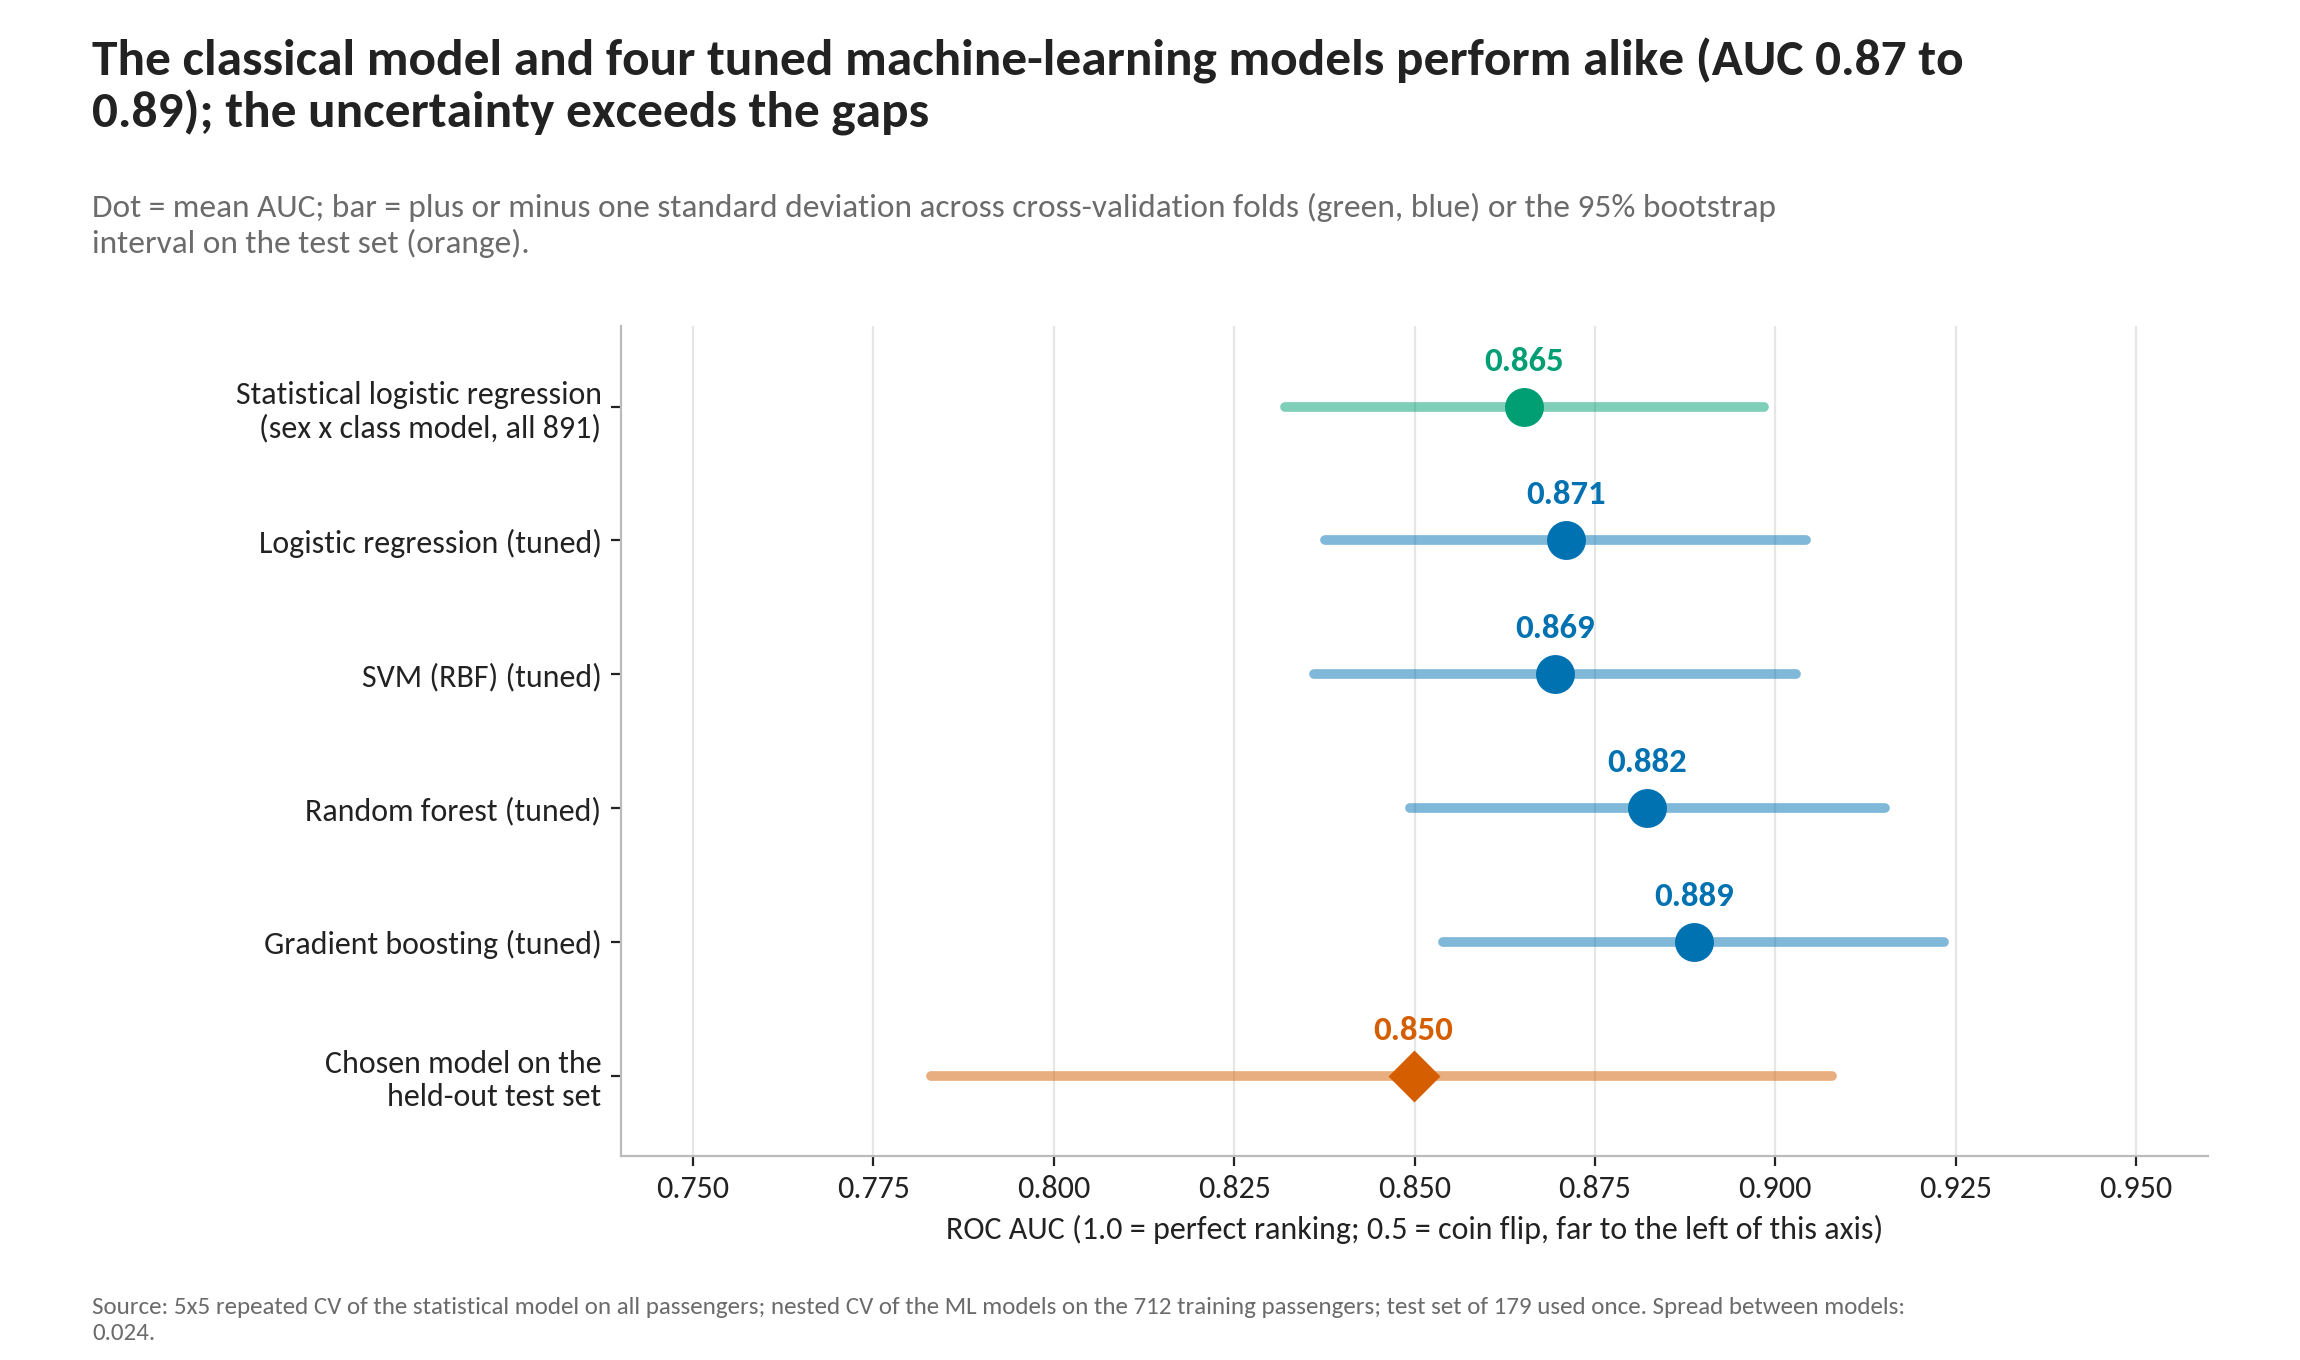

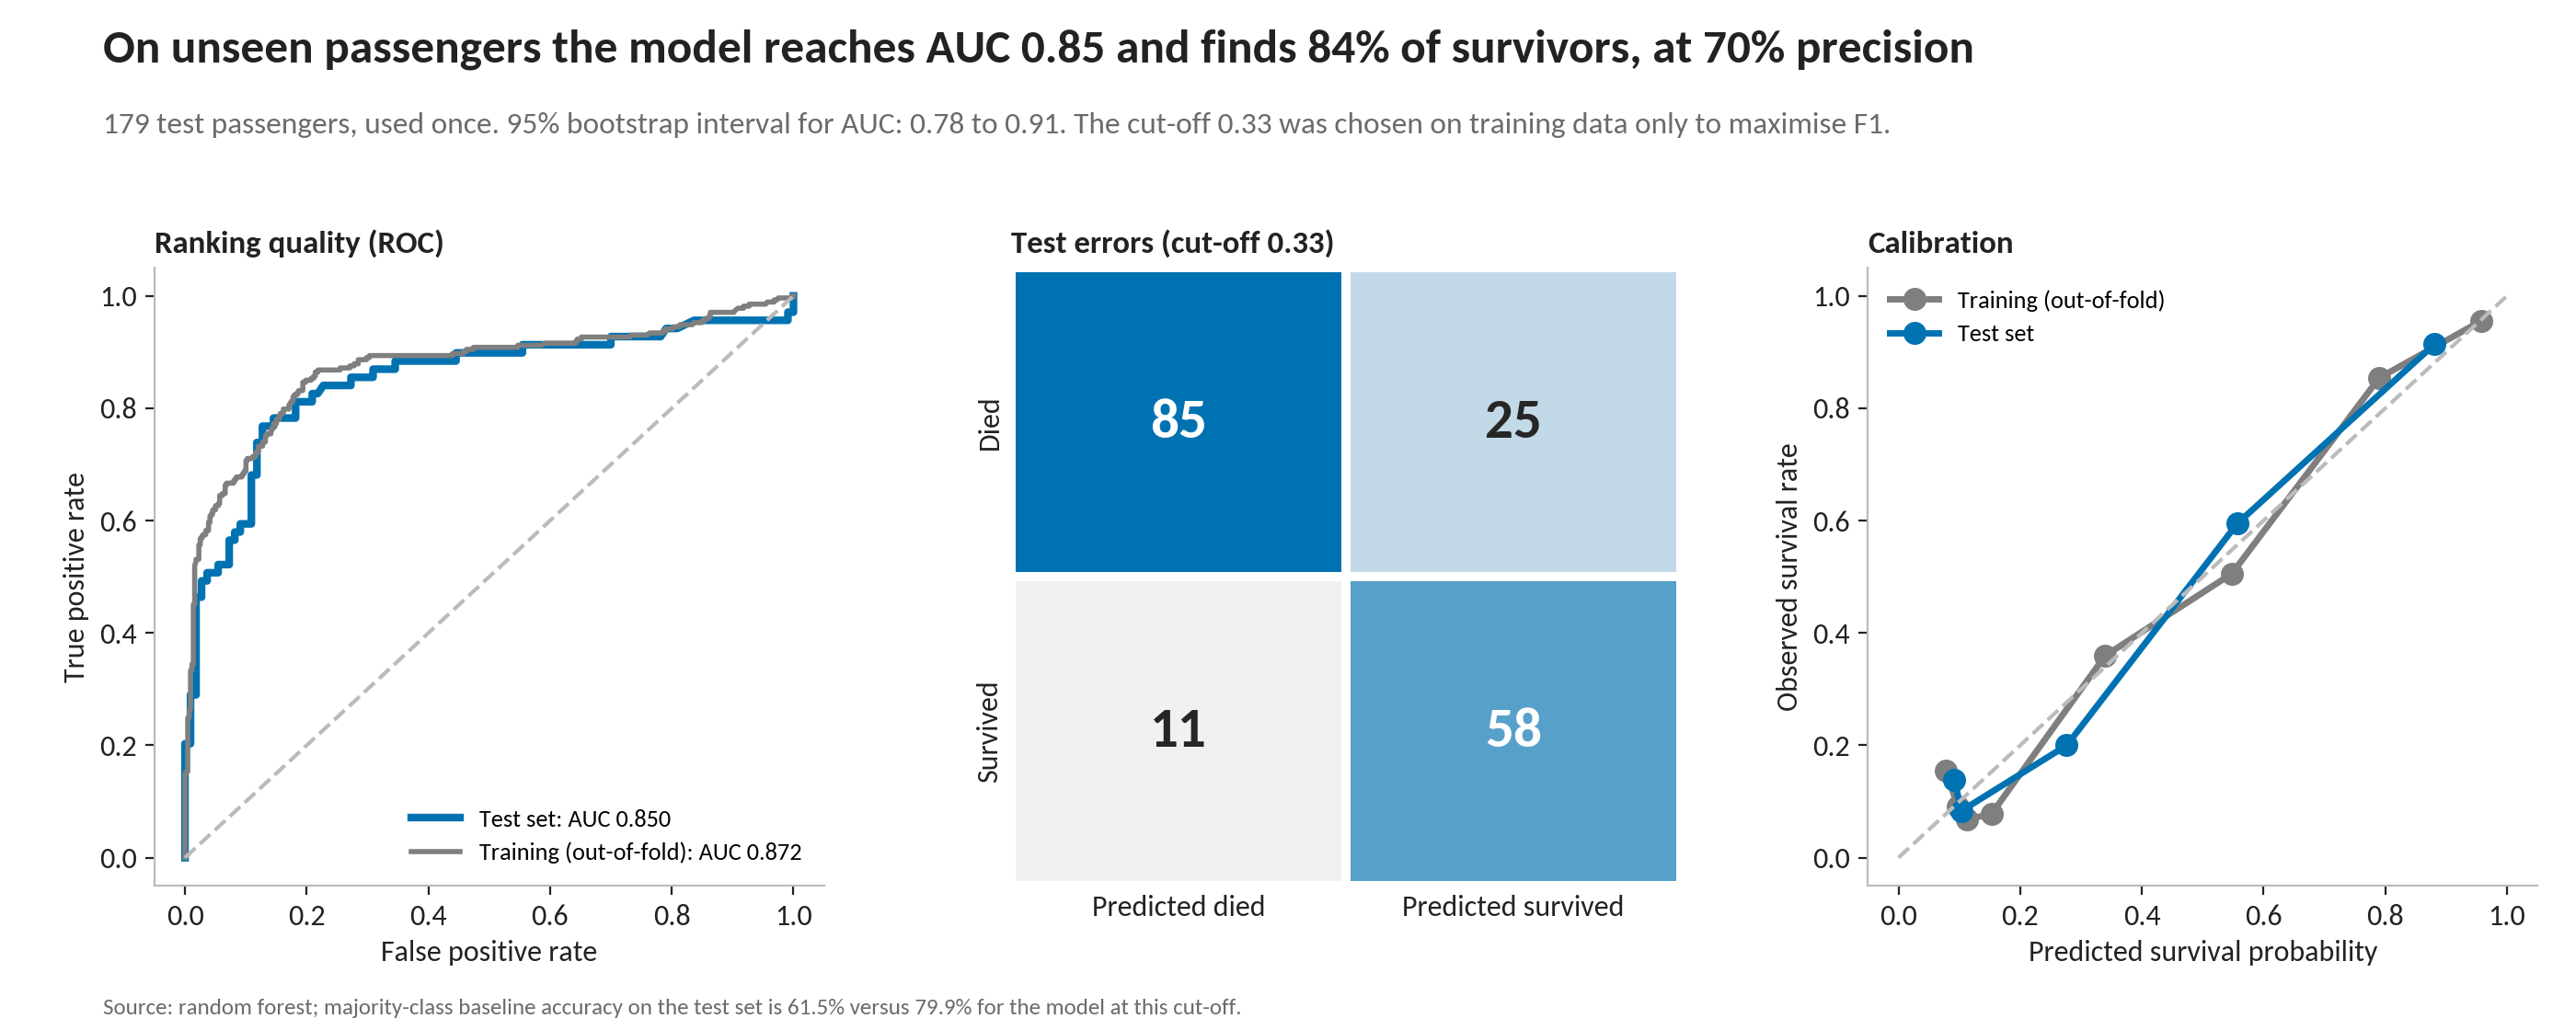

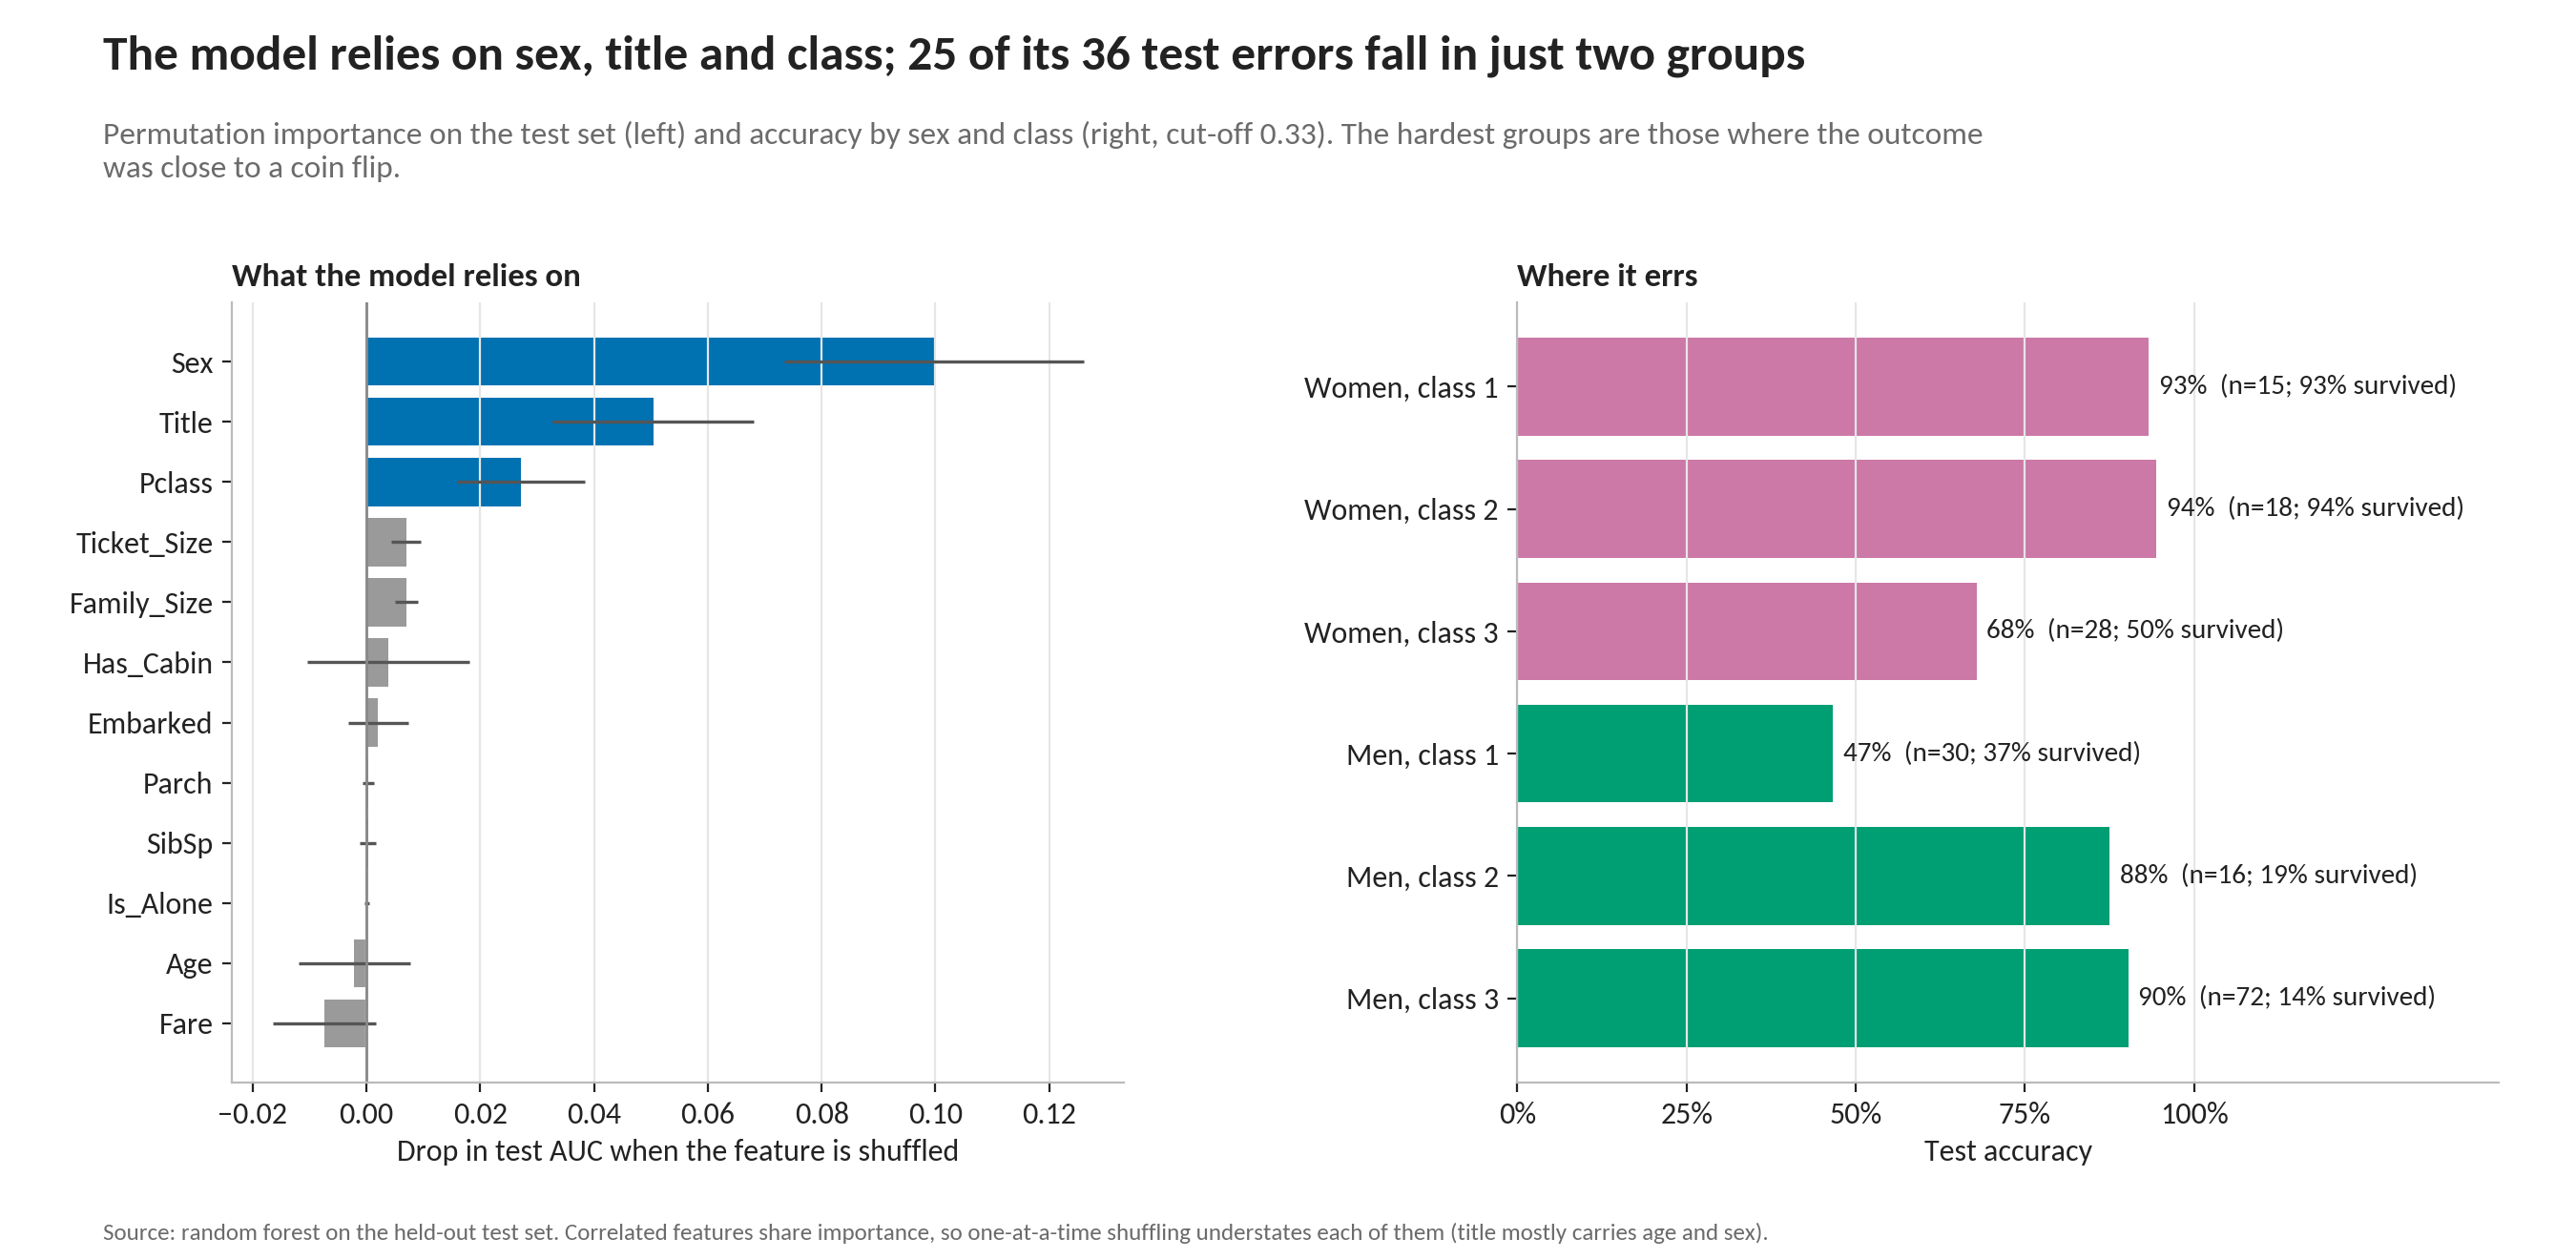

In [11]:
viz.fig_models(I, Mres); viz.fig_test(Mres, ctx); viz.fig_importance_errors(Mres)
for n in ("fig07_model_comparison", "fig08_test_performance", "fig09_importance_errors"): show(n, 1000)

**Reading the machine-learning results.** Four tuned models reach 0.87 to 0.89 AUC in nested cross-validation, within 0.02 of each other and of the classical logistic regression (0.865), while fold-to-fold variation is about 0.03: no model is demonstrably better. The rule selects the random forest, which scores AUC 0.850 (95% interval 0.78 to 0.91) and 80% accuracy on the 179 unseen passengers, against 61.5% for always predicting "died". Tuning mattered only for the random forest. The model relies on sex, title and class; its errors concentrate in first-class men and third-class women, where outcomes were close to a coin flip.

## 7. Integration: do the three approaches agree?
Each finding is checked against the evidence from exploratory analysis, statistical modelling and machine learning. The integrated pipeline must also reproduce every headline number reported in the weekly deliverables.

In [12]:
results = res.assemble(prov, log, E, I, Mres, fast=False)
tri = pd.DataFrame(results["integration"]); pd.set_option("display.max_colwidth", 120); display(tri)
cc = pd.DataFrame(results["crosscheck"]); display(cc); print(f"cross-check against weekly deliverables: {int(cc.match.sum())}/{len(cc)} reproduced")

,finding,eda,stats,ml,verdict
0,Sex was the strongest factor,Women 74% vs men 19% survived; Cramer's V = 0.54,"Adjusted odds ratio for women: 51 (1st), 100 (2nd), 6.3 (3rd class)",Largest permutation importance: 0.100 AUC drop,Consistent in all three approaches
1,"Class mattered, with a gradient",Survival 63% / 47% / 24% (1st/2nd/3rd); V = 0.34,Men: odds ratio 0.18 (2nd) and 0.17 (3rd) vs 1st class,Third-largest permutation importance: 0.027,Consistent
2,The women's advantage depends on class,"Gap between women and men: 60, 76 and 36 points in 1st, 2nd and 3rd class","Interaction likelihood-ratio test: chi-square = 33.5, p < 0.001",Learned without being specified: test accuracy 93% / 94% for 1st/2nd-class women but 68% for 3rd class,Consistent; hardest group for the model
3,"Age mattered mainly for the very young, and non-linearly",Children under 5: 27 of 40 survived (68%),Odds ratio per doubling of age 0.48 (0.39 to 0.61); straight-line form rejected (Box-Tidwell p = 0.001),Age itself adds -0.002: its information is carried by Title (importance 0.050),Consistent once the overlap with title is understood
4,Family size has an inverted-U effect,"Survival 30% alone, 58% in families of 2 to 4, 16% in families of 5 or more",Quadratic term significant (likelihood-ratio p = 0.006); linear term alone is not,Small contribution: 0.007,Real but modest
5,Port of embarkation is largely a composition effect,Cherbourg 55% vs Southampton 34%; V = 0.17,No significant independent effect after adjustment (joint likelihood-ratio p = 0.19),Negligible importance: 0.002,EDA association disappears under adjustment
6,Fare and cabin mostly reflect class,Class and log fare correlate at -0.69; cabin recorded for 81% of 1st vs 2% of 3rd class,Class and fare cannot both be entered without collinearity; class carries the effect,"Fare -0.007, cabin flag 0.004: little beyond class","Consistent: signposts, not separate causes"


,week,quantity,reference,reproduced,match
0,Week 1,Missing ages in the raw data,177,177.000,True
1,Week 1,Missing cabins in the raw data,687,687.000,True
2,Week 1,Columns in the cleaned dataset,26,26.000,True
3,Week 2,"Chi-square, survival vs sex",263.050,263.051,True
4,Week 2,"Cramer's V, survival vs sex",0.543,0.543,True
5,Week 3,AIC of the sex-by-class model,744.000,744.039,True
6,Week 3,"Odds ratio, first-class women vs men",50.600,50.594,True
7,Week 3,"LR chi-square, sex x class interaction",33.550,33.545,True
8,Week 3,"Cross-validated AUC, sex-by-class model",0.865,0.865,True
9,Week 4,Training / test split sizes,712 / 179,712 / 179,True


cross-check against weekly deliverables: 14/14 reproduced


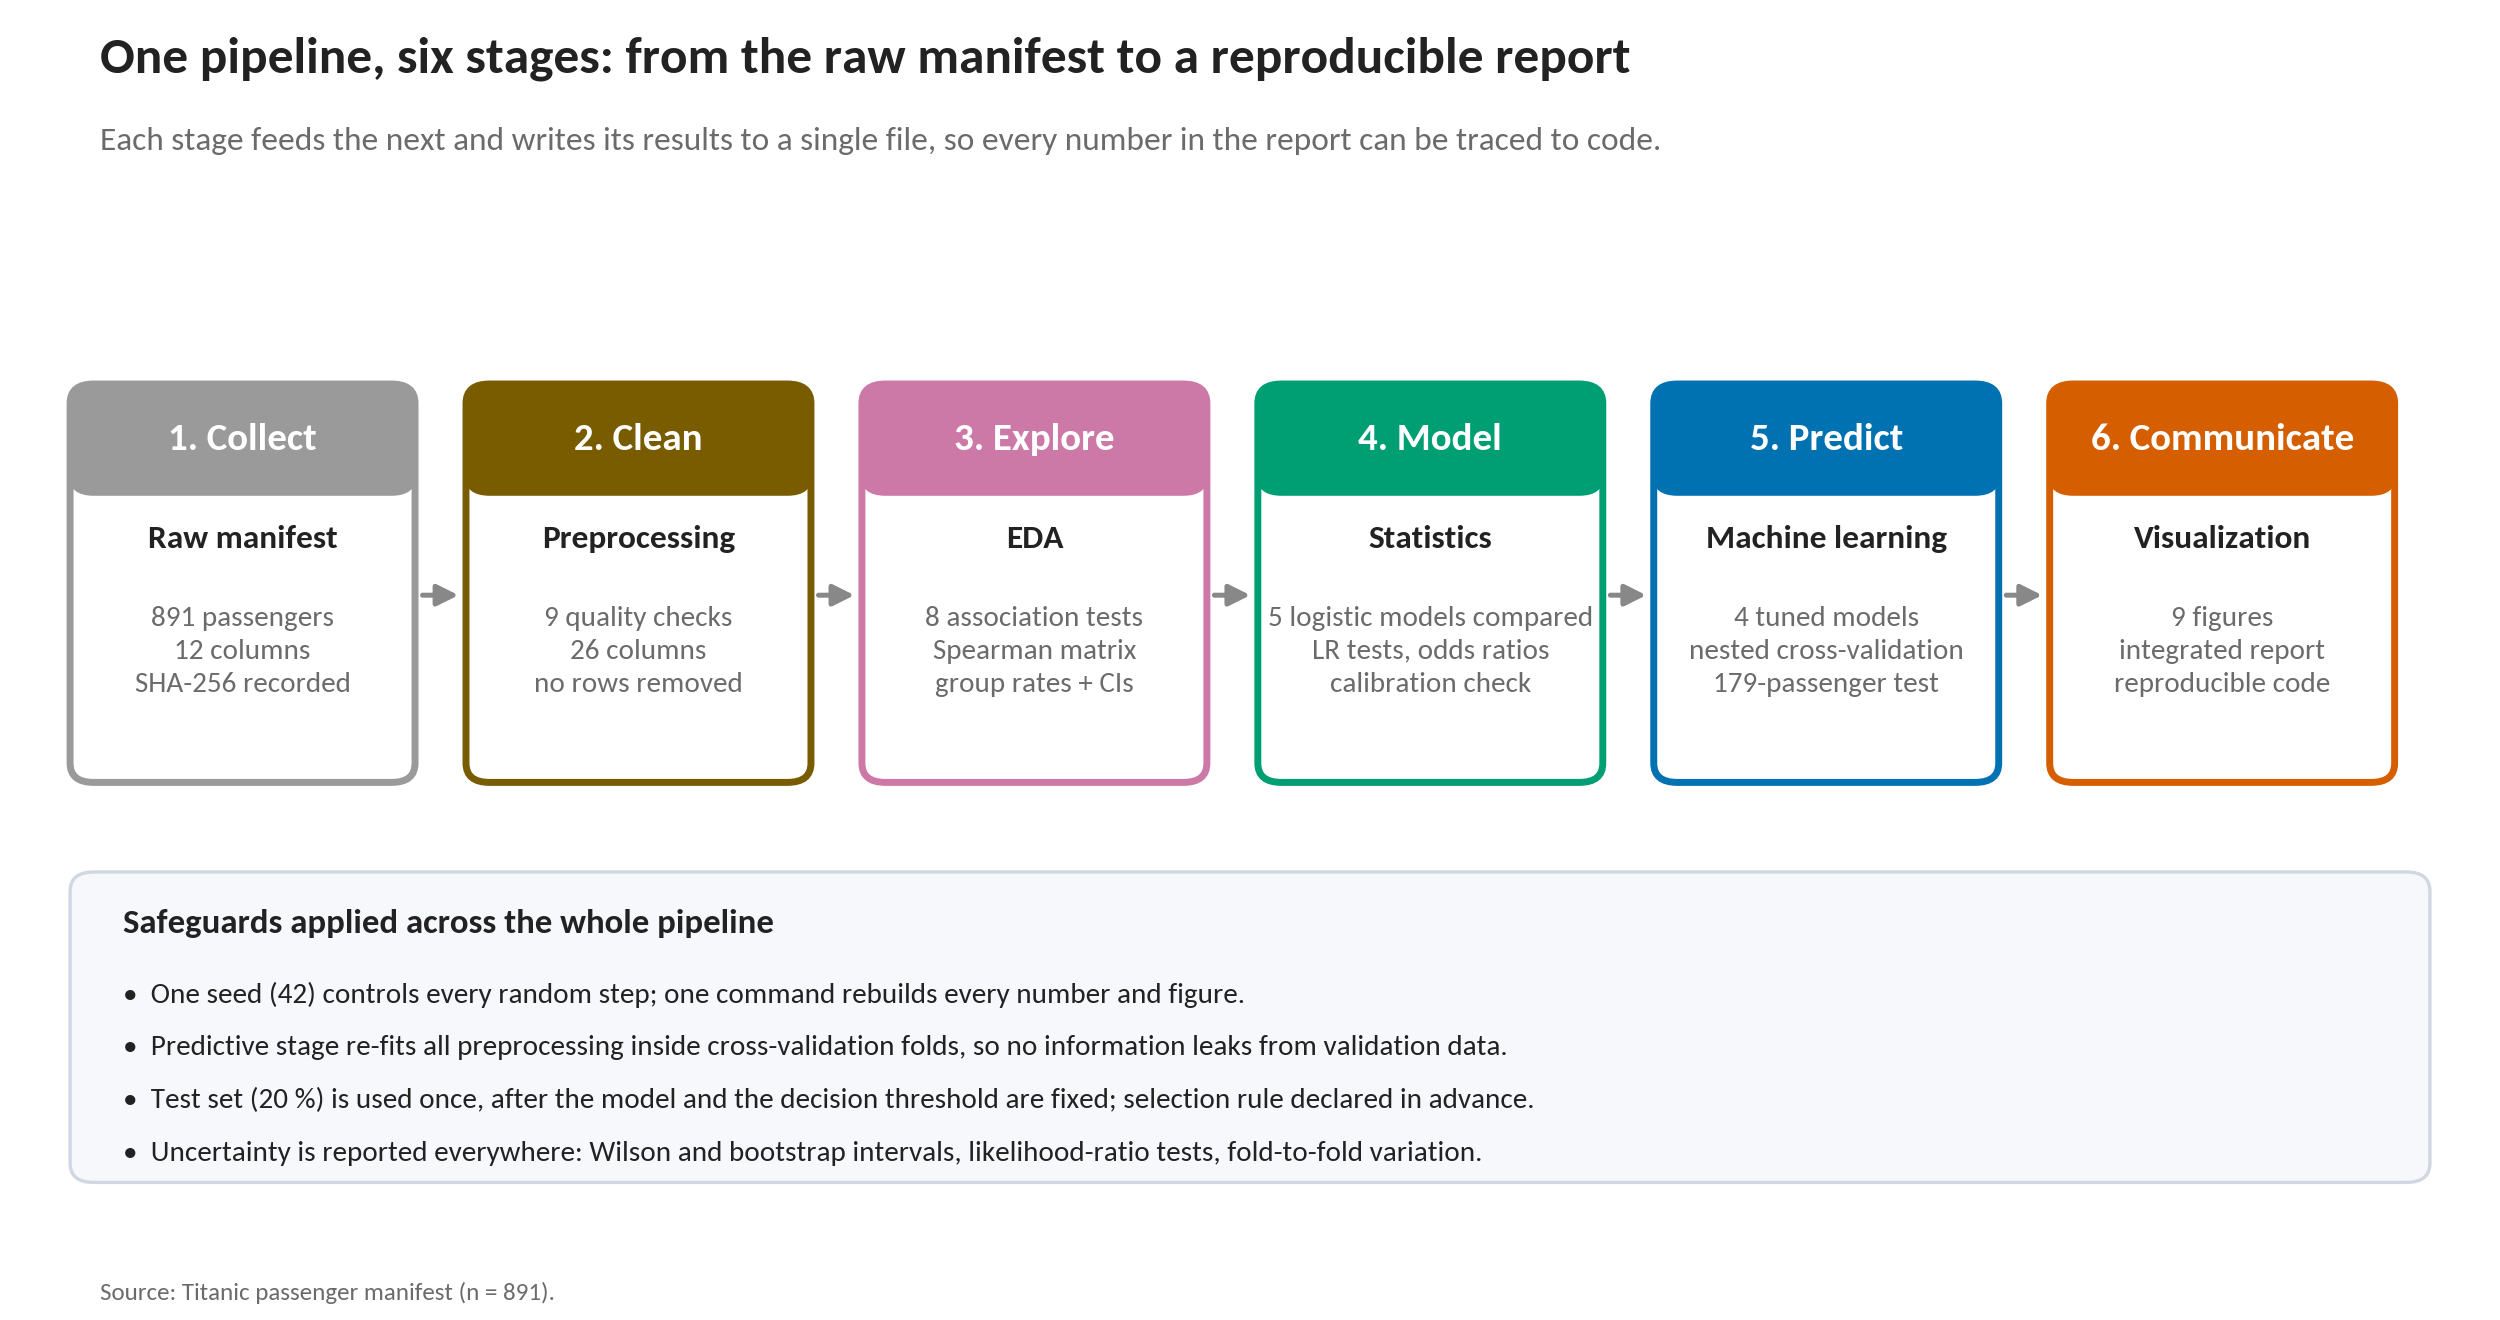

In [13]:
viz.fig_workflow(prov, log, E, I, Mres); show("fig01_workflow", 1000)

## 8. Save outputs and verify reproducibility
The notebook writes its own results file and compares it with the one produced by the command-line pipeline (`python run_pipeline.py`). The comparison ignores only wall-clock time.

In [14]:
import joblib
json.dump(results, open(config.RESULTS_DIR / "results_notebook.json", "w"), indent=1)
cli_path = config.RESULTS_DIR / "results.json"
if cli_path.exists():
    cli = json.load(open(cli_path))
    same = res.identical(cli, results)
    print("notebook results identical to the command-line run:", same)
    assert same, "Notebook and CLI results differ"
else:
    print("results/results.json not found; run `python run_pipeline.py` to enable the comparison")
print(f"notebook finished in {time.time() - T0:.0f} s")

notebook results identical to the command-line run: True
notebook finished in 182 s


## 9. Conclusions, limitations and next steps
- **What happened:** survival depended first on sex and class, in a way that varied by class (the women's advantage shrank from 76 points in second class to 36 in third); age mattered mostly for the youngest children; fare, cabin and port largely reflect class and who boarded where.
- **How well can we predict it:** AUC about 0.85 to 0.89 and about 80% accuracy; a simple logistic regression does as well as tuned ensembles.
- **Limitations:** observational historical data (associations, not causes); small groups (for example 94 first-class women); imputed ages; passengers are not independent (families); one 179-passenger test set gives wide intervals.
- **Next steps:** mixed-effects models for family groups, external validation on another dataset, probability calibration, and richer features such as cabin position.
- **Ethics:** the findings describe unequal access to safety in a historical disaster. They must not be used to rank people by sex or class in a real evacuation; the right lesson is to design procedures that do not depend on them.